# Criatura lendária: Tiamat
## Prevendo a adesão a depósitos a prazo em campanhas de telemarketing bancário

**Projeto final da disciplina ATP-203 — Aprendizado de Máquina**

**Autor:**   Angelo Quadros Zampieri
**Instituição:** Ilum Escola de Ciência  
**Professor:** Daniel R. Cassar  
**Casa, brasão, e frase perante o Rei Milu Iluminarius MLVI:** 

**Casa dos Feiticeiros Zampiricos**

<img src="brasao_desenhado.jpg" width="300">

*"Não entre em pânico! Você PASSARÁ, pois é melhor um figurante na luta, do que o papel principal em uma gaiola."*

### 1.1 A lenda

Vostrasirus Baba, o vidente, previu um dragão lendário atacando o reino neste semestre. Vossa Iluminância, o Rei Milu Iluminarius MLVI, convocou A Casa dos Feiticeiros Zampiricos porque ele não é realmente poderoso e nunca tirou nenhuma espada de lugar nenhum, só era um grande latifundiário. Os registros indicam que o monstro é o Tiamat, o dragão de cinco cabeças, que na verdade, é só a personificação da deusa primordial da mitologia babilônica e suméria, personificação das águas salgadas e do caos criador, que divide o céu e a terra, derrotá-la poderia trazer consequências graves.

Um dragão de cinco cabeças não se derrota com uma única estratégia. Neste trabalho, cada cabeça de Tiamat será enfrentada por um algoritmo de aprendizado de máquina diferente, todos treinados e otimizados sob as mesmas regras, e o Reino de Lumi (isto é, o leitor) decidirá qual deles merece a insígnia da Legião da Alvorada.

| Cabeças do Tiamat | Algoritmo / pipeline |
|:-:|:--|
| 1ª | Regressão logística (com normalização e PCA opcional) |
| 2ª | $k$-vizinhos mais próximos (com normalização e PCA opcional) |
| 3ª | Árvore de decisão |
| 4ª | Floresta aleatória |
| 5ª | Gradiente de boosting em histogramas |

### 1.2 O problema científico

Fora da fantasia, o problema real é o seguinte. Um banco de Portugal realizou, entre 2008 e 2010, campanhas de telemarketing para vender um **depósito a prazo**. Cada ligação gerou um registro com informações do cliente, do contexto da campanha e da economia no momento do contato, e o resultado final: o cliente aderiu (`yes`) ou não (`no`). Estes dados foram publicados por Moro, Cortez e Rita [1] e estão disponíveis no repositório da UCI [2].

**Pergunta de pesquisa:** *é possível prever, antes de ligar, se um cliente aderirá ao depósito a prazo, de forma a priorizar as ligações mais promissoras?*

Isto é um problema de **classificação binária supervisionada** com forte **desbalanceamento de classes** (cerca de 11% de adesões), o que tem consequências importantes para a escolha de métricas, que serão discutidas ao longo do trabalho.

### 1.3 Objetivos

1. Realizar uma análise exploratória dos dados.
2. Treinar um modelo **baseline** para servir de régua mínima.
3. Comparar **5 algoritmos/pipelines** diferentes, cada um com **100 tentativas** de otimização de hiperparâmetros no `optuna`, usando **validação cruzada** e evitando vazamento de dados.
4. Avaliar o desempenho final em um conjunto de teste que **não participa de nenhuma decisão de modelagem**.
5. Explicar o modelo escolhido (importância por permutação e dependência parcial).

### 1.4 Como navegar neste notebook

O notebook deve ser executado **de cima para baixo**. As seções são:

| Seção | Conteúdo |
|:-:|:--|
| 2 | Configuração inicial (bibliotecas e constantes) |
| 3 | Coleta e tratamento dos dados |
| 4 | Divisão em treino e teste (e checagem de vazamento) |
| 5 | Análise exploratória (apenas no conjunto de treino) |
| 6 | Métricas e validação cruzada |
| 7 | Modelo baseline |
| 8 | Estratégia de pré-processamento e otimização |
| 9 | As cinco cabeças de Tiamat (os 5 algoritmos) |
| 10 | Comparação dos algoritmos (validação cruzada) |
| 11 | Avaliação final no conjunto de teste |
| 12 | Explicação do modelo escolhido |
| 13 | Discussão dos resultados |
| 14 | Descrição do uso de IA neste trabalho |
| 15 | Referências |
| 16 | Conclusões e principais aprendizados |

> **Nota sobre tempo de execução:** a otimização de $5 \times 100$ tentativas com validação cruzada de 5 folds é demorada (de dezenas de minutos a algumas horas, dependendo do computador). Os estudos do `optuna` são salvos na pasta `estudos_optuna/` e, se o notebook for executado novamente, as tentativas já realizadas são reaproveitadas.

## 2. Configuração inicial

A célula abaixo deixa o `optuna` menos verboso (basta removê-la se quiser acompanhar a busca acontecendo).
Ela configura os avisos: deixa o `optuna` silencioso (só mostra avisos e erros, não cada tentativa) e esconde dois avisos esperados e repetitivos (`ExperimentalWarning` e o `Found unknown categories` do `OneHotEncoder`, que aparece quando uma categoria rara, como `default = yes`, não está em um fold de treino). Não muda nenhum resultado, só a poluição visual.

In [2]:
import warnings

import optuna

optuna.logging.set_verbosity(optuna.logging.WARNING)
warnings.filterwarnings("ignore", category=optuna.exceptions.ExperimentalWarning)

warnings.filterwarnings("ignore", message="Found unknown categories")

Ou seja, daqui em diante o `optuna` só avisa quando algo merece atenção, como um erro ou um aviso de biblioteca.

Definimos agora as constantes do projeto. Manter os valores importantes em constantes no início do notebook facilita a reprodutibilidade (principalmente a **semente aleatória**) e a manutenção do código.

A célula a seguir Importa as bibliotecas de uso geral (`os`, `numpy`, `pandas`, `matplotlib`, `seaborn`), define as constantes do projeto (arquivo de dados, 20% de teste, semente aleatória, 5 folds, 100 tentativas, 3 repetições da validação cruzada final) e cria a pasta `estudos_optuna/`.

In [1]:
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

NOME_DATASET = "bank-additional-full"
CAMINHO_DADOS = ("bank-additional-full.csv")
PASTA_ESTUDOS = "estudos_optuna"

TAMANHO_TESTE = 0.2
SEMENTE_ALEATORIA = 61455

NUM_FOLDS = 5
NUM_TENTATIVAS = 100
NUM_REPETICOES_CV = 3

os.makedirs(PASTA_ESTUDOS, exist_ok=True)

As constantes dimensionam o custo do trabalho: 5 algoritmos × 100 tentativas = 500 tentativas, cada uma treinando um modelo por fold, ou seja, **2.500 treinos** só na otimização. Mudar `SEMENTE_ALEATORIA` muda a divisão treino/teste, os folds e toda a busca, então os números do notebook só se reproduzem com a mesma semente.

## 3. Coleta e tratamento dos dados

### 3.1 Carregando os dados

O conjunto `bank-additional-full` [1, 2] tem **41.188 exemplos** e **20 atributos** de entrada, além do target `y`. Ele não é um conjunto sintético nem didático: são dados reais de uma operação bancária. O arquivo usa ponto e vírgula como separador.

esta célula lê o CSV (separado por `;`), guarda em `df_bruto` e mostra o número de linhas e colunas e uma prévia da tabela, só para conferir que a leitura funcionou.

In [3]:
df_bruto = pd.read_csv(CAMINHO_DADOS, sep=";")

print(f"O conjunto tem {df_bruto.shape[0]} exemplos e {df_bruto.shape[1]} colunas.")

df_bruto

O conjunto tem 41188 exemplos e 21 colunas.


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
41183,73,retired,married,professional.course,no,yes,no,cellular,nov,fri,...,1,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,yes
41184,46,blue-collar,married,professional.course,no,no,no,cellular,nov,fri,...,1,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,no
41185,56,retired,married,university.degree,no,yes,no,cellular,nov,fri,...,2,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,no
41186,44,technician,married,professional.course,no,no,no,cellular,nov,fri,...,1,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,yes


São 41.188 clientes (linhas) e 21 colunas: os 20 atributos de entrada mais o target `y`. A prévia sugere que o arquivo está em ordem cronológica: as primeiras linhas são de maio, com `euribor3m` = 4,857 e `emp.var.rate` = 1,1, enquanto as últimas são de novembro, com `euribor3m` = 1,028 e `emp.var.rate` = −1,1. O contexto econômico muda ao longo do arquivo, ponto que volta na seção 13.2.

 `df_bruto.info()` lista, para cada coluna, o tipo e quantos valores não nulos existem. Serve para ver quais colunas são numéricas ou texto e se há dados faltando.

In [4]:
df_bruto.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  object 
 2   marital         41188 non-null  object 
 3   education       41188 non-null  object 
 4   default         41188 non-null  object 
 5   housing         41188 non-null  object 
 6   loan            41188 non-null  object 
 7   contact         41188 non-null  object 
 8   month           41188 non-null  object 
 9   day_of_week     41188 non-null  object 
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  object 
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 non-null 

Todas as colunas têm 41.188 valores não nulos, então não há `NaN`. Há 10 colunas numéricas (5 inteiras e as 5 macroeconômicas, em decimal) e 11 de texto (as 10 categóricas e o `y`, ainda como `yes`/`no`). O conjunto ocupa só ~6,6 MB, então memória não é problema; o custo computacional vem dos 2.500 treinos da otimização.

Aqui, o código procura três tipos de sujeira nos dados: `NaN`, linhas totalmente duplicadas e o texto `"unknown"`, que neste conjunto faz o papel de valor ausente e imprime quantos `unknown` existem em cada coluna que os contém.

In [5]:
print(f"Valores ausentes (NaN): {df_bruto.isna().sum().sum()}")
print(f"Linhas totalmente duplicadas: {df_bruto.duplicated().sum()}")

# Neste conjunto, valores ausentes são codificados como o texto "unknown"
contagem_unknown = (df_bruto == "unknown").sum()
contagem_unknown[contagem_unknown > 0].sort_values(ascending=False)

Valores ausentes (NaN): 0
Linhas totalmente duplicadas: 12


default      8597
education    1731
housing       990
loan          990
job           330
marital        80
dtype: int64

Não tem nenhum `NaN` e há só 12 linhas totalmente duplicadas (a duplicação que realmente importa só aparece depois de remover `duration`, na seção 4). Os `unknown` estão em 6 atributos: `default` é o mais afetado (8.597 linhas, ~20,9%), seguido de `education` (1.731, ~4,2%), `housing` e `loan` (990 cada, ~2,4%), `job` (330, ~0,8%) e `marital` (80, ~0,2%). `housing` e `loan` têm exatamente a mesma contagem, o que sugere (hipótese não verificada aqui) que faltam nas mesmas linhas, isto é, em clientes sem esse bloco de informação cadastral.

Não há `NaN`, mas há valores ausentes **codificados como `"unknown"`** em seis atributos categóricos. Como `"unknown"` pode carregar informação (por exemplo, clientes que não quiseram informar se têm inadimplência), vamos tratá-lo como **mais uma categoria**, em vez de imputar valores. Existem também algumas linhas totalmente duplicadas, que serão tratadas na etapa de divisão dos dados algumas etapas à frente.

### 3.2 Dicionário de dados

| Atributo | Tipo | Descrição |
|:--|:-:|:--|
| `age` | numérico | idade do cliente |
| `job` | categórico | tipo de ocupação |
| `marital` | categórico | estado civil |
| `education` | categórico | nível de escolaridade |
| `default` | categórico | possui crédito inadimplente? |
| `housing` | categórico | possui financiamento imobiliário? |
| `loan` | categórico | possui empréstimo pessoal? |
| `contact` | categórico | tipo de comunicação do contato (celular ou telefone fixo) |
| `month` | categórico | mês do último contato |
| `day_of_week` | categórico | dia da semana do último contato |
| `duration` | numérico | duração da última ligação, em segundos (**será removido**, ver abaixo) |
| `campaign` | numérico | número de contatos nesta campanha para este cliente |
| `pdays` | numérico | dias desde o último contato de campanha anterior (999 = nunca contatado) |
| `previous` | numérico | número de contatos antes desta campanha |
| `poutcome` | categórico | resultado da campanha anterior |
| `emp.var.rate` | numérico | taxa de variação do emprego (indicador trimestral) |
| `cons.price.idx` | numérico | índice de preços ao consumidor (mensal) |
| `cons.conf.idx` | numérico | índice de confiança do consumidor (mensal) |
| `euribor3m` | numérico | taxa Euribor de 3 meses (diária) |
| `nr.employed` | numérico | número de empregados (trimestral) |
| `y` | **target** | o cliente aderiu ao depósito a prazo? (`yes`/`no`) |

### 3.2.1 Guia dos atributos: famílias, valores possíveis e tratamento

Para facilitar a leitura das análises (taxas de adesão, importância por permutação, dependência parcial), os 20 atributos de entrada podem ser agrupados em cinco famílias:

| Família | Atributos | O que descrevem |
|:--|:--|:--|
| Perfil do cliente | `age`, `job`, `marital`, `education` | Quem é a pessoa |
| Situação financeira | `default`, `housing`, `loan` | Crédito inadimplente, financiamento imobiliário e empréstimo pessoal |
| Contexto do contato atual | `contact`, `month`, `day_of_week`, `campaign` | Como, quando e quantas vezes o cliente foi contatado nesta campanha |
| Histórico com o banco | `pdays`, `previous`, `pdays_nunca_contatado`, `poutcome` | O que aconteceu em campanhas anteriores |
| Contexto econômico | `emp.var.rate`, `cons.price.idx`, `cons.conf.idx`, `euribor3m`, `nr.employed` | Estado da economia no período. **Iguais para todos os clientes contatados no mesmo período**, por isso funcionam como um "relógio" |

**Atributos categóricos e seus valores:**

| Atributo | Valores | Observação |
|:--|:--|:--|
| `job` | `admin.`, `blue-collar`, `entrepreneur`, `housemaid`, `management`, `retired`, `self-employed`, `services`, `student`, `technician`, `unemployed`, `unknown` | 12 categorias |
| `marital` | `divorced`, `married`, `single`, `unknown` | Segundo a documentação do conjunto [2], `divorced` inclui viúvos |
| `education` | `illiterate`, `basic.4y`, `basic.6y`, `basic.9y`, `high.school`, `professional.course`, `university.degree`, `unknown` | Tem ordem natural, mas é tratada como categoria sem ordem |
| `default`, `housing`, `loan` | `yes`, `no`, `unknown` | `default = yes` aparece só 3 vezes |
| `contact` | `cellular`, `telephone` | Celular ou telefone fixo |
| `month` | `mar`, `apr`, `may`, `jun`, `jul`, `aug`, `sep`, `oct`, `nov`, `dec` | Não há janeiro nem fevereiro |
| `day_of_week` | `mon`, `tue`, `wed`, `thu`, `fri` | Só dias úteis |
| `poutcome` | `failure`, `nonexistent`, `success` | `nonexistent` = não foi contatado em campanha anterior |

**Atributos numéricos:**

| Atributo | Faixa aproximada | Observação |
|:--|:--|:--|
| `age` | 17 a 98 anos | Relação com a adesão em forma de U (EDA, seção 5.2) |
| `campaign` | inteiro ≥ 1 | Inclui o contato atual; cauda longa, com poucos clientes contatados dezenas de vezes |
| `pdays` | dias | Após o tratamento, `0` significa "nunca contatado"; deve ser lido junto com `pdays_nunca_contatado` |
| `previous` | inteiro ≥ 0 | Contatos feitos antes desta campanha |
| `pdays_nunca_contatado` | 0 ou 1 | Criado por nós na seção 3.3 |
| `emp.var.rate` | −3,4 a +1,4 | Variação da taxa de emprego (trimestral) |
| `cons.price.idx` | 92,2 a 94,8 | Índice de preços ao consumidor (mensal) |
| `cons.conf.idx` | −50,8 a −26,9 | Índice de confiança do consumidor (mensal) |
| `euribor3m` | ~0,6 a ~5,0 | Taxa Euribor de 3 meses (diária) |
| `nr.employed` | na casa de 5 mil | Número de empregados (trimestral) |

**Como cada família entra nos modelos:** na regressão logística e no $k$-NN, os numéricos são normalizados e os categóricos viram colunas `one-hot`; nas árvores e na floresta, os numéricos entram como estão (as árvores não são sensíveis à escala) e os categóricos viram `one-hot`; no boosting, os categóricos viram inteiros e são tratados nativamente pelo algoritmo.

### 3.3 Decisões de tratamento

Três decisões de tratamento são tomadas aqui. Todas são transformações **determinísticas, linha a linha** (não aprendem nada dos dados), portanto não causam vazamento de dados.

1. **Remoção de `duration`.** A própria documentação do conjunto [2] alerta que a duração da ligação só é conhecida *depois* que a ligação acontece, e que ela determina fortemente o resultado (uma ligação de 0 segundos é sempre `no`). Se o objetivo é **decidir para quem ligar**, usar `duration` é um caso clássico de **vazamento de informação do futuro**: o modelo teria um desempenho irrealisticamente alto e inútil na prática. Por isso, ela é removida.
2. **Tratamento de `pdays`.** O valor `999` significa "nunca contatado anteriormente" e não é uma distância de 999 dias: se mantido, ele distorceria algoritmos baseados em distância ou em modelos lineares. Criamos o atributo binário `pdays_nunca_contatado` e substituímos o `999` por `0` na coluna `pdays` (o par de colunas, juntas, mantém toda a informação original).
3. **Target numérico.** Convertemos `y` para $1$ (`yes`, classe positiva) e $0$ (`no`).

Esta célula aplica as três decisões da seção 3.3: remove `duration`, cria `pdays_nunca_contatado` (trocando o `999` de `pdays` por `0`) e converte `y` em 0/1. Depois define as listas `ATRIBUTOS_NUMERICOS` e `ATRIBUTOS_CATEGORICOS`, usadas em todo o resto do notebook, e reordena as colunas.

In [6]:
df = df_bruto.copy()

# 1) Remoção do atributo que só existe depois da ligação
df = df.drop(columns=["duration"])

# 2) pdays = 999 significa "nunca contatado"
df["pdays_nunca_contatado"] = (df["pdays"] == 999).astype(int)
df.loc[df["pdays"] == 999, "pdays"] = 0

# 3) Target numérico (1 = aderiu)
df["y"] = (df["y"] == "yes").astype(int)

ATRIBUTOS_NUMERICOS = [
    "age",
    "campaign",
    "pdays",
    "previous",
    "pdays_nunca_contatado",
    "emp.var.rate",
    "cons.price.idx",
    "cons.conf.idx",
    "euribor3m",
    "nr.employed",
]

ATRIBUTOS_CATEGORICOS = [
    "job",
    "marital",
    "education",
    "default",
    "housing",
    "loan",
    "contact",
    "month",
    "day_of_week",
    "poutcome",
]

ATRIBUTOS = ATRIBUTOS_NUMERICOS + ATRIBUTOS_CATEGORICOS
TARGET = ["y"]

df = df.reindex(ATRIBUTOS + TARGET, axis=1)

print(f"Número de atributos de entrada: {len(ATRIBUTOS)}")
df.head()

Número de atributos de entrada: 20


,age,campaign,pdays,previous,pdays_nunca_contatado,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,...,marital,education,default,housing,loan,contact,month,day_of_week,poutcome,y
0,56,1,0,0,1,1.1,93.994,-36.4,4.857,5191.0,...,married,basic.4y,no,no,no,telephone,may,mon,nonexistent,0
1,57,1,0,0,1,1.1,93.994,-36.4,4.857,5191.0,...,married,high.school,unknown,no,no,telephone,may,mon,nonexistent,0
2,37,1,0,0,1,1.1,93.994,-36.4,4.857,5191.0,...,married,high.school,no,yes,no,telephone,may,mon,nonexistent,0
3,40,1,0,0,1,1.1,93.994,-36.4,4.857,5191.0,...,married,basic.6y,no,no,no,telephone,may,mon,nonexistent,0
4,56,1,0,0,1,1.1,93.994,-36.4,4.857,5191.0,...,married,high.school,no,no,yes,telephone,may,mon,nonexistent,0


Continuamos com 20 atributos de entrada: saiu `duration` e entrou `pdays_nunca_contatado`. São 10 numéricos e 10 categóricos. Nas primeiras linhas, `pdays_nunca_contatado = 1` e `pdays = 0` indicam clientes nunca contatados antes: a informação original foi preservada, sem o valor `999` enganoso. O target `y` já está como 0/1.

## 4. Divisão em treino e teste

### 4.1 Evitando vazamento por dados redundantes

Como vimos em aula (vazamento de dados), se existirem exemplos idênticos ou quase idênticos, é possível que um deles caia no treino e o outro no teste, e o modelo seria "avaliado" em algo que já viu. Neste conjunto, depois de remover `duration`, é comum que clientes com exatamente os mesmos atributos apareçam mais de uma vez (os atributos macroeconômicos são os mesmos para todos os contatos de um mesmo período).

Seguimos a estratégia da disciplina: **identificar grupos de exemplos com atributos iguais** e usar o `GroupShuffleSplit` para que cada grupo caia inteiro em treino **ou** em teste. Aqui não precisamos arredondar nenhum atributo, pois a idade e os indicadores macroeconômicos já têm poucos valores distintos.

O conjunto de teste ficará **guardado** até a seção 11 e **não será usado para nenhuma decisão** (nem de hiperparâmetros, nem de escolha de algoritmo).

Esta célula Cria um identificador de grupo para cada combinação única dos 20 atributos (`groupby(...).ngroup()`) e usa o `GroupShuffleSplit` para sortear 20% dos *grupos* para o teste, de modo que clientes idênticos fiquem sempre do mesmo lado. Depois separa `X` e `y` de treino e de teste. A semente fixa garante a mesma divisão a cada execução.

In [7]:
from sklearn.model_selection import GroupShuffleSplit

grupos = df.groupby(ATRIBUTOS).ngroup()

print(f"Número de exemplos: {len(df)}")
print(f"Grupos únicos: {grupos.nunique()}")
print(f"Maior grupo: {grupos.value_counts().max()} exemplos idênticos")

gss = GroupShuffleSplit(
    n_splits=1,
    test_size=TAMANHO_TESTE,
    random_state=SEMENTE_ALEATORIA,
)

indices_treino, indices_teste = next(
    gss.split(df[ATRIBUTOS], df[TARGET], groups=grupos)
)

df_treino = df.iloc[indices_treino].reset_index(drop=True)
df_teste = df.iloc[indices_teste].reset_index(drop=True)

grupos_treino = grupos.iloc[indices_treino].reset_index(drop=True)

X_treino = df_treino.reindex(ATRIBUTOS, axis=1)
y_treino = df_treino.reindex(TARGET, axis=1).squeeze()

X_teste = df_teste.reindex(ATRIBUTOS, axis=1)
y_teste = df_teste.reindex(TARGET, axis=1).squeeze()

print(f"Exemplos de treino: {len(df_treino)}")
print(f"Exemplos de teste: {len(df_teste)}")

Número de exemplos: 41188
Grupos únicos: 39167
Maior grupo: 7 exemplos idênticos
Exemplos de treino: 32934
Exemplos de teste: 8254


Os 41.188 exemplos formam 39.167 grupos únicos, ou seja, ~2.021 linhas (4,9%) são cópias exatas de outra (eram só 12 antes de remover `duration`). O maior grupo tem 7 clientes idênticos. A divisão ficou com 32.934 exemplos de treino (79,96%) e 8.254 de teste (20,04%): não é exatamente 80/20 porque o sorteio é por grupo, não por linha.

Como o split é agrupado, ele não pode ser estratificado automaticamente. Vamos verificar se as proporções da classe positiva ficaram parecidas nos dois conjuntos.

Como a divisão por grupos não é estratificada, comparamos a quantidade e a proporção de adesões no conjunto todo, no treino e no teste.

In [8]:
proporcoes = pd.DataFrame(
    {
        "Conjunto": ["Total", "Treino", "Teste"],
        "Exemplos": [len(df), len(df_treino), len(df_teste)],
        "Adesões (y = 1)": [df["y"].sum(), y_treino.sum(), y_teste.sum()],
        "Proporção de adesões (%)": [
            df["y"].mean() * 100,
            y_treino.mean() * 100,
            y_teste.mean() * 100,
        ],
    }
)

proporcoes.round(2)

,Conjunto,Exemplos,Adesões (y = 1),Proporção de adesões (%)
0,Total,41188,4640,11.27
1,Treino,32934,3691,11.21
2,Teste,8254,949,11.50


A taxa de adesão é 11,27% no total, 11,21% no treino (3.691 adesões) e 11,50% no teste (949 adesões): a diferença é de menos de 0,3 ponto percentual. O teste representa bem o desbalanceamento do treino, então comparar as métricas da validação cruzada com as do teste é justo.

### 4.2 Checando o split

Como na aula de vazamento de dados, comparamos o histograma das **menores distâncias** (Manhattan) entre os exemplos de treino e treino (cada exemplo contra seu vizinho mais próximo, excluindo ele mesmo) com o das menores distâncias entre treino e teste. Em um split saudável, os exemplos de teste **não podem estar mais próximos do treino** do que os exemplos de treino estão uns dos outros. O teste de hipótese de Mann-Whitney testa se `treino x treino` é estatisticamente *menor* que `treino x teste`.

Para as distâncias fazerem sentido, os dados são normalizados (o normalizador é ajustado **apenas no treino**) e os atributos categóricos são transformados em colunas `one-hot`. Por custo computacional, usamos amostras aleatórias de 3.000 exemplos para cada comparação.

Esta célula verifica se a divisão deixou vazamento por proximidade. Normaliza os dados (ajuste só no treino), sorteia 3.000 exemplos de treino e 3.000 de teste, mede a distância Manhattan de cada um ao seu vizinho mais próximo no treino (no caso treino × treino, ignorando o próprio exemplo), plota os histogramas e aplica o teste de Mann-Whitney, cuja hipótese alternativa é que `treino x treino` seja menor que `treino x teste`.

p-valor = 4.67471714760338e-09
Rejeitar H0: split saudável.


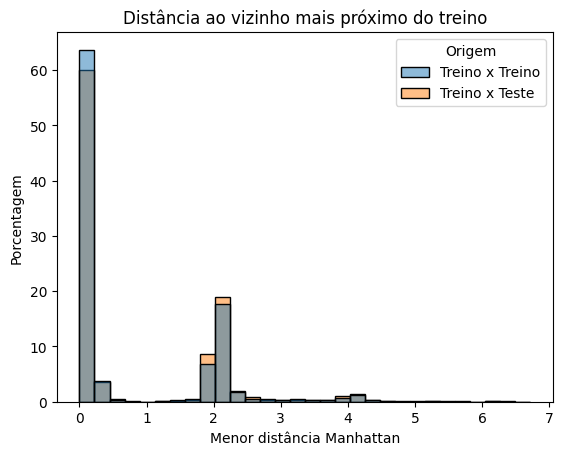

In [9]:
from scipy.stats import mannwhitneyu
from sklearn.compose import make_column_transformer
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder

TAMANHO_AMOSTRA_DIST = 3000
NIVEL_CONFIANCA = 0.95

transformador_dist = make_column_transformer(
    (MinMaxScaler(), ATRIBUTOS_NUMERICOS),
    (OneHotEncoder(handle_unknown="ignore", sparse_output=False), ATRIBUTOS_CATEGORICOS),
)

transformador_dist.fit(X_treino)  # ajuste apenas no treino
X_treino_norm = transformador_dist.transform(X_treino)
X_teste_norm = transformador_dist.transform(X_teste)

gerador = np.random.default_rng(SEMENTE_ALEATORIA)
amostra_treino = gerador.choice(len(X_treino_norm), TAMANHO_AMOSTRA_DIST, replace=False)
amostra_teste = gerador.choice(len(X_teste_norm), TAMANHO_AMOSTRA_DIST, replace=False)

vizinhos = NearestNeighbors(n_neighbors=2, metric="manhattan", n_jobs=-1)
vizinhos.fit(X_treino_norm)

# o primeiro vizinho de um exemplo de treino é ele mesmo, então pegamos o segundo
treino_treino = vizinhos.kneighbors(X_treino_norm[amostra_treino])[0][:, 1]
treino_teste = vizinhos.kneighbors(X_teste_norm[amostra_teste], n_neighbors=1)[0].ravel()

distancias = pd.concat(
    [
        pd.DataFrame({"valor": treino_treino, "Origem": "Treino x Treino"}),
        pd.DataFrame({"valor": treino_teste, "Origem": "Treino x Teste"}),
    ],
    ignore_index=True,
)

bins = np.histogram_bin_edges(distancias["valor"], bins=30)

eixo = sns.histplot(
    data=distancias,
    x="valor",
    hue="Origem",
    bins=bins,
    alpha=0.5,
    stat="percent",
    common_norm=False,
)
eixo.set(
    xlabel="Menor distância Manhattan",
    ylabel="Porcentagem",
    title="Distância ao vizinho mais próximo do treino",
)

resultado = mannwhitneyu(treino_treino, treino_teste, alternative="less")
pvalor = resultado.pvalue

print("p-valor =", pvalor)

if pvalor < 1 - NIVEL_CONFIANCA:
    print("Rejeitar H0: split saudável.")
else:
    print("Não rejeitar H0: pode haver vazamento!")

O p-valor é ≈ 4,7·10⁻⁹, então rejeitamos $H_0$: o teste está, em média, um pouco mais longe do treino do que o treino de si mesmo. Dois cuidados na leitura. (1) O p-valor é minúsculo por causa do tamanho das amostras, não porque a diferença seja grande: os histogramas quase se sobrepõem. (2) Nos dois casos cerca de 60% dos exemplos têm um vizinho a menos de ~0,2 (perfis quase idênticos, que diferem, por exemplo, em um ano de idade) e há um segundo pico perto de 2, que corresponde a clientes que diferem em exatamente uma categoria (cada categoria trocada soma 2 na distância Manhattan com `one-hot`). Ou seja, cópias exatas não atravessam a fronteira, mas quase-duplicatas atravessam; isso é inevitável e pode deixar as estimativas de desempenho levemente otimistas.

**Interpretação:** se o teste rejeita $H_0$, os exemplos de teste estão, em geral, *mais longe* do treino do que os exemplos de treino estão entre si, que é exatamente o comportamento esperado de um split sem vazamento por redundância. Note que, como o conjunto tem muitos clientes com perfis parecidos (mesmo emprego, estado civil, período macroeconômico...), nenhuma divisão aleatória consegue afastar completamente o teste do treino; o que garantimos é que **cópias exatas não atravessam a fronteira**.

## 5. Análise exploratória dos dados

Toda a análise exploratória é feita **somente no conjunto de treino**. Se olhássemos o conjunto de teste e tomássemos decisões baseadas nele (por exemplo, descartar um atributo porque "parece inútil"), estaríamos deixando informação do teste vazar para a modelagem.

### 5.1 O target: um problema desbalanceado

Esta célula conta quantos clientes do treino aderiram e não aderiram e desenha as duas barras com a contagem e a porcentagem de cada classe.

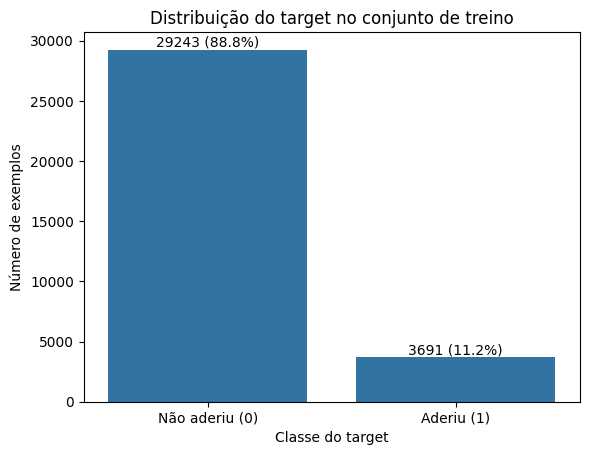

In [10]:
contagem = df_treino["y"].value_counts().sort_index()
taxa_adesao = df_treino["y"].mean()

eixo = sns.barplot(x=["Não aderiu (0)", "Aderiu (1)"], y=contagem.values)

for barra, valor in zip(eixo.patches, contagem.values):
    eixo.annotate(
        f"{valor} ({valor / len(df_treino) * 100:.1f}%)",
        (barra.get_x() + barra.get_width() / 2, barra.get_height()),
        ha="center",
        va="bottom",
    )

eixo.set(
    xlabel="Classe do target",
    ylabel="Número de exemplos",
    title="Distribuição do target no conjunto de treino",
);

No treino, 29.243 clientes não aderiram (88,8%) e 3.691 aderiram (11,2%), cerca de 8 não-adesões para cada adesão. É esse desbalanceamento que justifica a escolha das métricas: prever sempre "não" já acerta 88,8% sem aprender nada.

Só cerca de **11% dos clientes aderem**. Isto tem uma consequência prática imediata: um modelo que **sempre responde "não aderiu"** acertaria cerca de 89% das vezes, sem aprender absolutamente nada. Logo, **acurácia não é uma boa métrica aqui** (voltaremos a isso na seção 6).

### 5.2 Atributos numéricos

A célula abaixo compara, para cada classe, a distribuição de quatro atributos numéricos: `age`, `campaign` (cortado em 15 contatos por causa da cauda longa), `pdays` (só clientes contatados antes) e `previous` (cortado em 6). Os histogramas usam densidade e `common_norm=False`, para comparar o *formato* das distribuições e não o tamanho das classes.

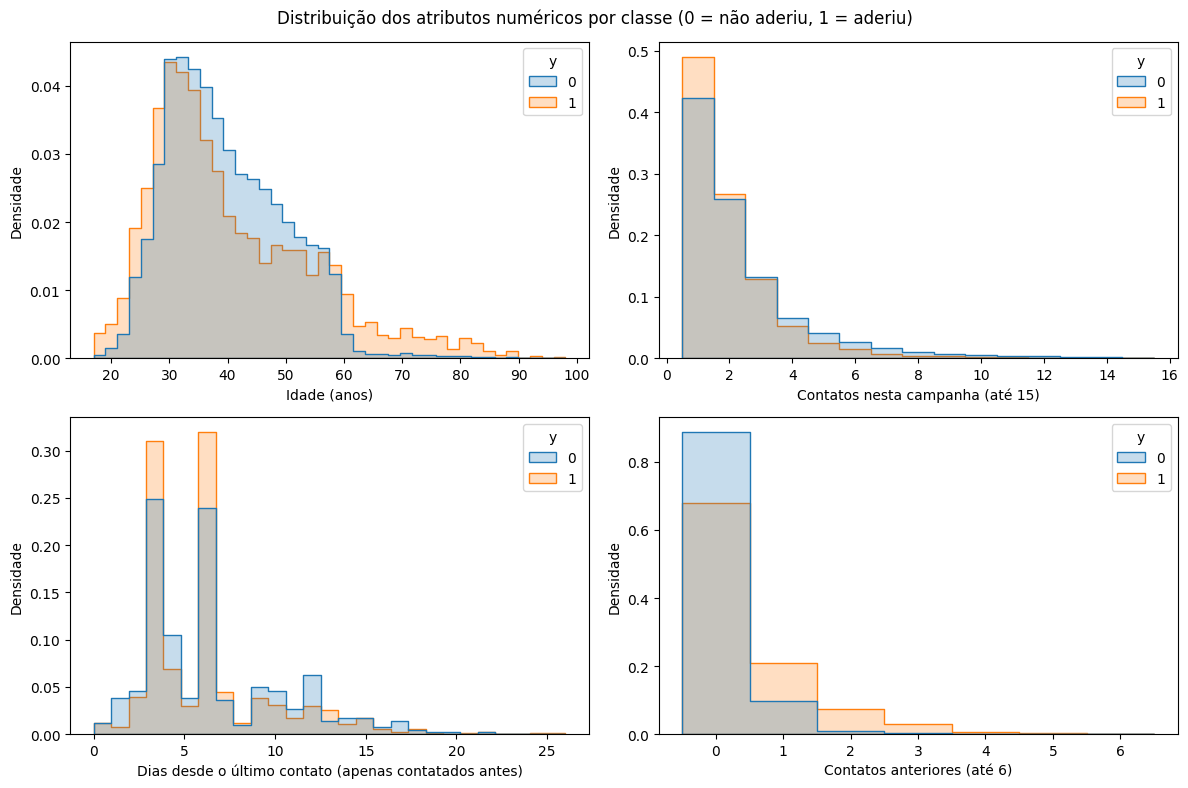

In [11]:
fig, eixos = plt.subplots(2, 2, figsize=(12, 8))

# idade
sns.histplot(
    data=df_treino, x="age", hue="y", stat="density", common_norm=False,
    element="step", bins=40, ax=eixos[0, 0],
)
eixos[0, 0].set(xlabel="Idade (anos)", ylabel="Densidade")

# número de contatos nesta campanha (cauda longa: cortamos em 15)
sns.histplot(
    data=df_treino.loc[df_treino["campaign"] <= 15], x="campaign", hue="y",
    stat="density", common_norm=False, element="step", discrete=True, ax=eixos[0, 1],
)
eixos[0, 1].set(xlabel="Contatos nesta campanha (até 15)", ylabel="Densidade")

# dias desde o último contato (apenas quem foi contatado antes)
sns.histplot(
    data=df_treino.loc[df_treino["pdays_nunca_contatado"] == 0], x="pdays", hue="y",
    stat="density", common_norm=False, element="step", bins=27, ax=eixos[1, 0],
)
eixos[1, 0].set(xlabel="Dias desde o último contato (apenas contatados antes)", ylabel="Densidade")

# contatos anteriores
sns.histplot(
    data=df_treino.loc[df_treino["previous"] <= 6], x="previous", hue="y",
    stat="density", common_norm=False, element="step", discrete=True, ax=eixos[1, 1],
)
eixos[1, 1].set(xlabel="Contatos anteriores (até 6)", ylabel="Densidade")

fig.suptitle("Distribuição dos atributos numéricos por classe (0 = não aderiu, 1 = aderiu)")
fig.tight_layout()

**O que os resultados mostram que:**

`age`: quem adere está sobre-representado abaixo de ~30 e acima de ~60 anos; entre ~35 e 55 anos predominam os que não aderem. `campaign`: as duas classes se concentram em 1 a 3 contatos, e a classe positiva tem um pouco mais de peso em 1 contato. `pdays`: há picos em ~3 e ~6 dias nas duas classes (padrão do calendário das campanhas), ainda mais marcados entre os que aderem. `previous`: cerca de 89% dos que não aderiram e ~68% dos que aderiram nunca foram contatados antes; a partir de 1 contato prévio, os positivos pesam mais. Em nenhum gráfico as classes se separam bem, o que confirma a dificuldade do problema.

As distribuições (normalizadas por classe, para compensar o desbalanceamento) mostram que a classe positiva tem proporcionalmente mais clientes nas faixas extremas de idade, menos contatos repetidos na campanha atual e mais contatos prévios. Nenhum atributo, sozinho, separa as classes, o que sugere que o problema é genuinamente difícil.

### 5.3 Indicadores macroeconômicos e correlações

Aqui, desenhamos um boxplot de cada indicador macroeconômico separado por classe do target, para ver se esses indicadores se distribuem de forma diferente entre quem aderiu e quem não aderiu.

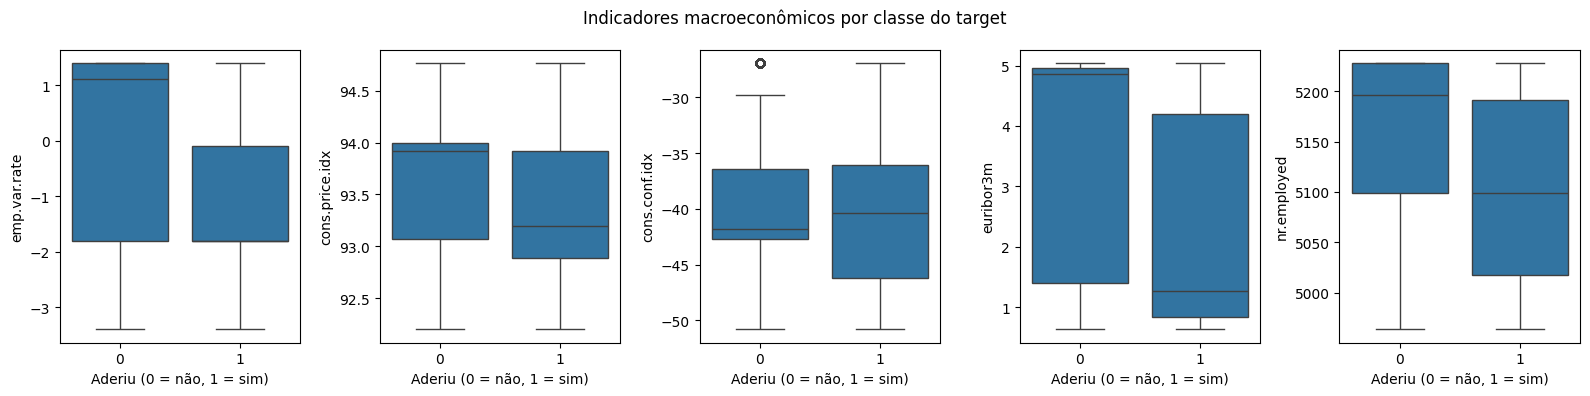

In [12]:
ATRIBUTOS_MACRO = ["emp.var.rate", "cons.price.idx", "cons.conf.idx", "euribor3m", "nr.employed"]

fig, eixos = plt.subplots(1, 5, figsize=(16, 4))

for eixo, atributo in zip(eixos, ATRIBUTOS_MACRO):
    sns.boxplot(data=df_treino, x="y", y=atributo, ax=eixo)
    eixo.set(xlabel="Aderiu (0 = não, 1 = sim)", ylabel=atributo)

fig.suptitle("Indicadores macroeconômicos por classe do target")
fig.tight_layout()

De acordo com os resultados, quem aderiu aparece com valores mais baixos em quatro dos cinco indicadores: `emp.var.rate` (mediana em torno de −1,8 contra +1,1), `euribor3m` (≈1,3 contra ≈4,9), `nr.employed` (≈5.100 contra ≈5.200) e `cons.price.idx` (≈93,2 contra ≈93,9). `cons.conf.idx` quase não difere (medianas de ≈−40 e ≈−42). Uma leitura plausível, mas não testada aqui, é que as adesões se concentram em períodos de juros baixos. Como as caixas se sobrepõem bastante, nenhum indicador sozinho separa as classes.

Aqui ccalculamos a correlação de Pearson entre todos os atributos numéricos e o target e a mostra como mapa de calor (só o triângulo inferior, para não repetir valores).

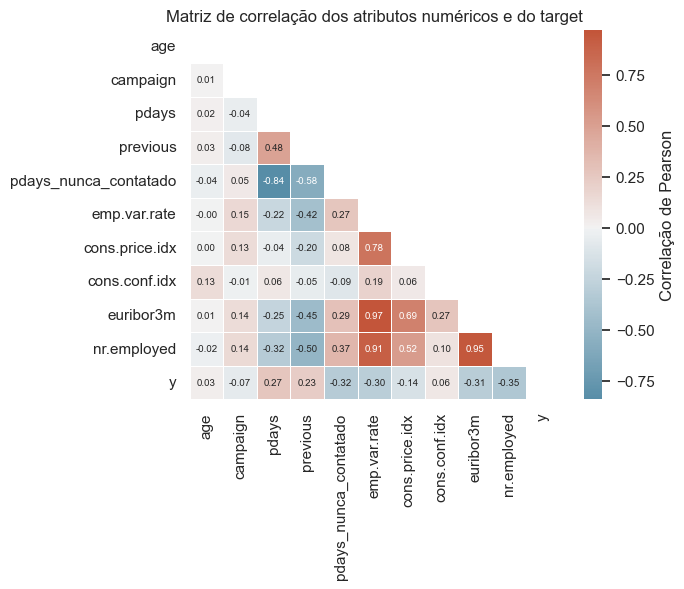

In [13]:
sns.set_theme(style="white")

m_corr = df_treino.reindex(ATRIBUTOS_NUMERICOS + TARGET, axis=1).corr()
mascara = np.triu(np.ones_like(m_corr, dtype=bool))
mapa_de_cor = sns.diverging_palette(230, 20, as_cmap=True)

eixo = sns.heatmap(
    m_corr,
    mask=mascara,
    cmap=mapa_de_cor,
    center=0,
    square=True,
    linewidths=0.5,
    annot=True,
    fmt=".2f",
    annot_kws={"size": 7},
    cbar_kws={"label": "Correlação de Pearson"},
)
eixo.set(title="Matriz de correlação dos atributos numéricos e do target")

sns.set_theme()

**Entre os atributos:*

`euribor3m` × `emp.var.rate` = 0,97, 

`euribor3m` × `nr.employed` = 0,95 

`emp.var.rate` × `nr.employed` = 0,91, 

há uma redundância quase total 
(`cons.price.idx` também se correlaciona, 0,78 com `emp.var.rate`). 

Além disso, `pdays` × `pdays_nunca_contatado` = −0,84, consequência da forma como codificamos "nunca contatado".

*Com o target:* todas as correlações são fracas; as maiores em módulo são `nr.employed` (−0,35), `pdays_nunca_contatado` (−0,32), `euribor3m` (−0,31), `emp.var.rate` (−0,30), `pdays` (+0,27) e `previous` (+0,23). `age` tem correlação ≈ 0,03, mas isso não significa que seja inútil: o Pearson só enxerga relações lineares, e o gráfico anterior mostrou que a relação da idade com a adesão tem forma de U.

Duas observações importantes:

- `emp.var.rate`, `euribor3m` e `nr.employed` são **fortemente correlacionados entre si** (correlações acima de 0,9). Eles basicamente descrevem o mesmo fenômeno: o momento econômico. Esta **multicolinearidade** é um problema para modelos lineares (coeficientes instáveis) e não prejudica árvores; o PCA e a regularização $L1$/$L2$ que o `optuna` poderá escolher nas buscas são formas de lidar com ela.
- Esses indicadores variam por período, então funcionam como uma espécie de "relógio" do conjunto de dados. Voltaremos a este ponto na discussão.



### 5.4 Atributos categóricos

Para cada categoria, calculamos a **taxa de adesão** (porcentagem de `y = 1`). A linha vermelha tracejada é a taxa geral do treino.

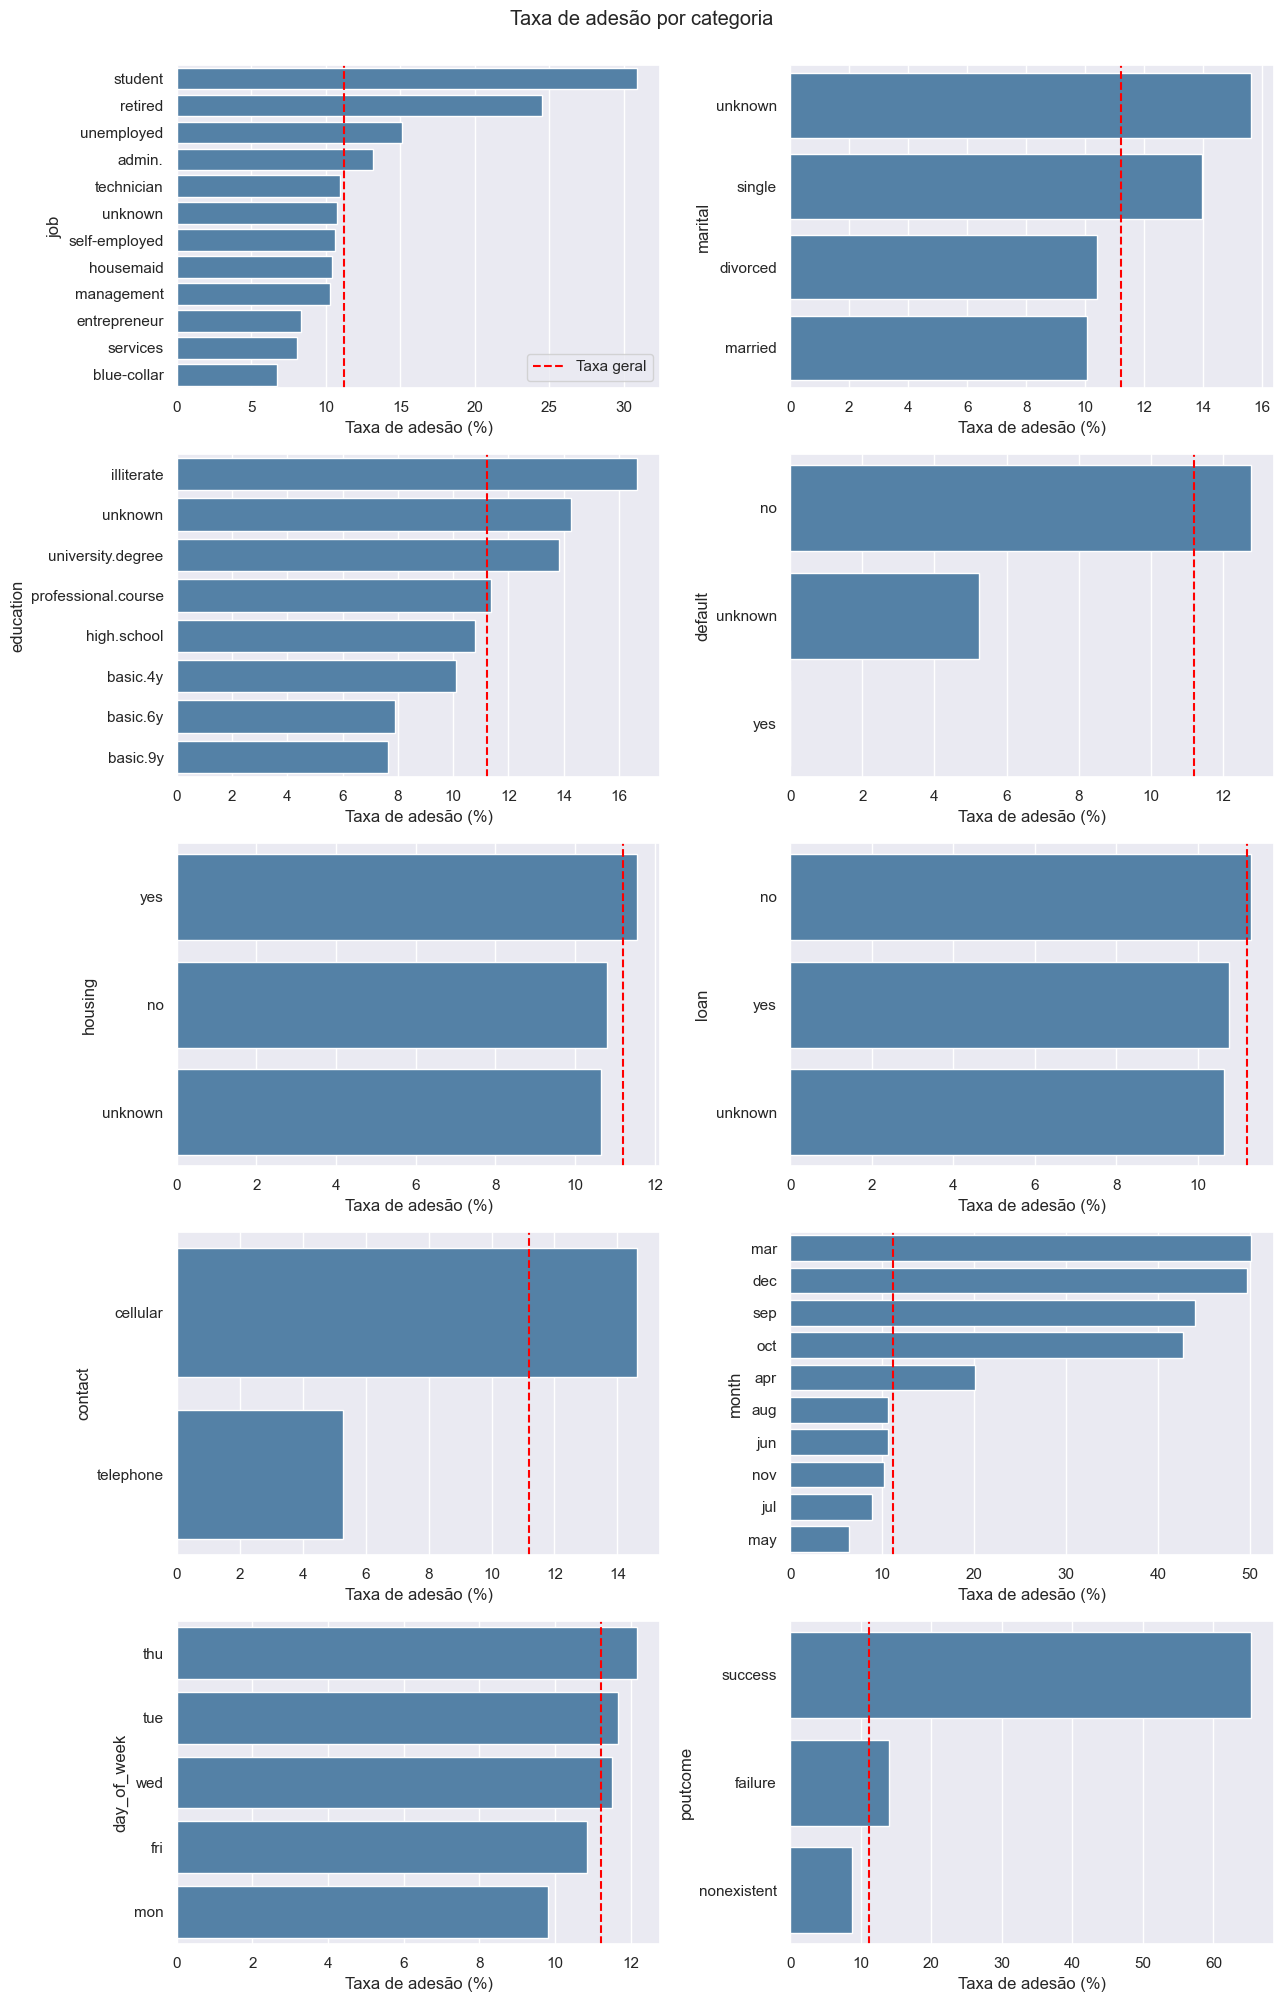

In [14]:
fig, eixos = plt.subplots(5, 2, figsize=(13, 20))

for eixo, atributo in zip(eixos.ravel(), ATRIBUTOS_CATEGORICOS):
    taxas = df_treino.groupby(atributo)["y"].mean().sort_values(ascending=False) * 100

    sns.barplot(x=taxas.values, y=taxas.index, orient="h", ax=eixo, color="steelblue")
    eixo.axvline(taxa_adesao * 100, linestyle="--", color="red", label="Taxa geral")
    eixo.set(xlabel="Taxa de adesão (%)", ylabel=atributo)

eixos[0, 0].legend(loc="lower right")
fig.suptitle("Taxa de adesão por categoria", y=1.0)
fig.tight_layout()

As maiores diferenças estão em `poutcome` (`success` ~65% contra ~9% em `nonexistent`), `month` (março, dezembro, setembro e outubro entre ~43% e 50%, contra ~7% em maio), `contact` (celular ~15% contra ~5% no telefone fixo), `job` (estudantes ~31% e aposentados ~25% contra ~7% em `blue-collar`) e `default` (`no` ~13% contra ~5% em `unknown`; `yes` não tem nenhuma adesão, mas são só 3 casos). `education` e `marital` variam moderadamente (a categoria `illiterate` aparece no topo, mas provavelmente com pouquíssimos exemplos), e `housing`, `loan` e `day_of_week` ficam bem perto da média, o que sugere que carregam pouca informação.

a célula abaixo monta uma tabela com todas as categorias que têm pelo menos 100 exemplos no treino (para evitar taxas calculadas sobre amostras minúsculas) e mostra as 8 com maior taxa de adesão.

In [15]:
linhas = []

for atributo in ATRIBUTOS_CATEGORICOS:
    resumo = df_treino.groupby(atributo)["y"].agg(["count", "mean"])
    resumo = resumo.loc[resumo["count"] >= 100]
    for categoria, linha in resumo.iterrows():
        linhas.append(
            {
                "Atributo": atributo,
                "Categoria": categoria,
                "Exemplos": int(linha["count"]),
                "Taxa de adesão (%)": linha["mean"] * 100,
            }
        )

df_categorias = pd.DataFrame(linhas).sort_values("Taxa de adesão (%)", ascending=False)

df_categorias.head(8).round(1)

,Atributo,Categoria,Exemplos,Taxa de adesão (%)
49,poutcome,success,1087,65.3
37,month,mar,455,50.1
34,month,dec,151,49.7
41,month,sep,448,44.0
40,month,oct,573,42.8
8,job,student,673,30.9
5,job,retired,1374,24.5
32,month,apr,2105,20.0


No topo estão `poutcome = success` (65,3%, 1.087 exemplos), março (50,1%, 455), dezembro (49,7%, 151), setembro (44,0%, 448), outubro (42,8%, 573), estudantes (30,9%, 673), aposentados (24,5%, 1.374) e abril (20,0%, 2.105). Quatro das oito linhas são meses com poucos contatos, e quanto menor o número de exemplos, mais incerta é a taxa: para dezembro (n = 151) a margem de erro de 95% é de aproximadamente ±8 pontos percentuais, contra ±4,6 para março (n = 455). `poutcome = success`, estudantes e aposentados são os sinais mais sólidos, por combinarem taxa alta e muitos exemplos.

Observe o `poutcome = success` (clientes que já aderiram em campanhas anteriores) com taxa de adesão muito acima da média: é um excelente preditor, mas atinge poucos clientes. Meses como março, setembro, outubro e dezembro também têm taxas altas, porém com **poucos contatos**, o que significa que a taxa observada nestes meses é uma estimativa mais incerta. Já `unknown` em atributos como `default` está associado a taxas **menores** que a geral, o que justifica tratá-lo como categoria própria, e não como "dado faltante a ser imputado".

### 5.5 Resumo da exploração

- O problema é **desbalanceado** (~11% de classe positiva): exige métricas adequadas e atenção na validação.
- Existem **atributos redundantes** (indicadores macroeconômicos): faz sentido deixar o `optuna` testar PCA para os algoritmos sensíveis a isso.
- Há atributos com escalas muito diferentes (`age` em dezenas, `nr.employed` em milhares): algoritmos baseados em distância ou em gradiente (k-NN, regressão logística) **precisam de normalização**; árvores não.
- Nenhum atributo isolado resolve o problema, então esperamos que modelos capazes de combinar atributos de forma não linear (florestas, boosting) tenham vantagem. Esta é uma hipótese que os experimentos vão testar.



## 6. Métricas e validação cruzada

### 6.1 Por que não usar a acurácia?

Lembremos da matriz de confusão para classificação binária (aula de classificação binária e de outras métricas):

| | Predito = 1 | Predito = 0 |
|:-:|:-:|:-:|
| **Real = 1** | VP | FN |
| **Real = 0** | FP | VN |

A acurácia, $\mathrm{ACC} = \frac{VP + VN}{VP + FP + VN + FN}$, é dominada pela classe majoritária. No nosso caso, um modelo que sempre diz "não" tem ~89% de acurácia e **zero** utilidade para o banco, pois nunca identifica um cliente que aderiria. (A Dra. Diana Didatolov não deixaria este exercício "para o leitor atento": está resolvido logo abaixo, na seção do baseline.)

### 6.2 Métricas escolhidas

O modelo, na prática, **ordena os clientes pela probabilidade de adesão** para que o banco ligue primeiro aos mais promissores. Por isso, preferimos métricas que avaliam essa ordenação e que **não dependem de escolher um limiar de probabilidade**:

- **Área sob a curva ROC (ROC-AUC):** probabilidade de que o modelo atribua uma probabilidade maior a um exemplo positivo aleatório do que a um negativo aleatório. 0,5 equivale a um sorteio; 1,0 é perfeito.
- **Precisão média (*average precision*, AP):** resume a **curva precisão $\times$ sensibilidade** (PR). A precisão é $\mathrm{PPV} = \frac{VP}{VP + FP}$ e a sensibilidade é $\mathrm{TPR} = \frac{VP}{VP + FN}$. Para um modelo sem nenhum poder preditivo, a AP é igual à **proporção de positivos** (~0,11 aqui), ao contrário da ROC-AUC, que vale 0,5. A AP é uma estimativa da área sob a curva PR (PR-AUC), a métrica recomendada para dados desbalanceados [7].

Em problemas desbalanceados, a curva PR é mais informativa que a ROC, porque a ROC pode parecer otimista quando há muitos negativos (a taxa de falsos positivos é "diluída" pelo grande número de verdadeiros negativos) [7]. Por isso, **a AP será a métrica de otimização do `optuna`** e a ROC-AUC será reportada como métrica complementar. Na seção 11, também discutiremos o limiar de decisão e as métricas baseadas nos rótulos preditos (precisão, sensibilidade e estatística F1).

### 6.3 Validação cruzada sem vazamento

Para comparar hiperparâmetros e algoritmos usamos validação cruzada de 5 folds **apenas dentro do conjunto de treino**. Dois cuidados:

1. **Estratificada**, para que cada fold mantenha ~11% de positivos.
2. **Agrupada**, para que exemplos idênticos (mesmo grupo da seção 4) nunca fiquem em folds diferentes. Usamos o `StratifiedGroupKFold`.

Os folds são **definidos uma única vez** e reutilizados por todos os algoritmos e todas as tentativas do `optuna`. Assim, todos são comparados exatamente sob as mesmas condições, e a diferença de desempenho não é efeito de uma divisão mais "sortuda".

A partir de agora, cada célula de código irá possuir duas notas, uuma chamada `O que esta célula faz` para guiar o leitor a entender o que está acontecendo, e uma outra célula chamada `O que os resultados mostram` para ajudar o leitor a entender como os dados foram interpretados, em último caso, caso o código não retorne nada, terá uma nota `O que isso significa` que tentará dar uma explicaçã breve sobre o que aconteceu.

> **O que esta célula faz.** Cria os 5 folds da validação cruzada com `StratifiedGroupKFold` (estratificado pelo target e agrupado pelos grupos da seção 4, embaralhado, semente fixa). Os folds são criados uma única vez (`FOLDS`) e reutilizados por todos os algoritmos e tentativas. A tabela mostra o tamanho e a taxa de adesão de cada fold de validação.

In [16]:
from sklearn.model_selection import StratifiedGroupKFold

sgkf = StratifiedGroupKFold(
    n_splits=NUM_FOLDS,
    shuffle=True,
    random_state=SEMENTE_ALEATORIA,
)

FOLDS = list(sgkf.split(X_treino, y_treino, groups=grupos_treino))

resumo_folds = pd.DataFrame(
    [
        {
            "Fold": i + 1,
            "Exemplos de treino": len(ind_tr),
            "Exemplos de validação": len(ind_val),
            "Adesões na validação (%)": y_treino.iloc[ind_val].mean() * 100,
        }
        for i, (ind_tr, ind_val) in enumerate(FOLDS)
    ]
)

resumo_folds.round(2)

,Fold,Exemplos de treino,Exemplos de validação,Adesões na validação (%)
0,1,26363,6571,11.16
1,2,26363,6571,11.55
2,3,26331,6603,11.03
3,4,26365,6569,11.37
4,5,26314,6620,10.94


> **O que os resultados mostram.** Cada fold treina com ~26,3 mil exemplos e valida com ~6,6 mil. A taxa de adesão na validação varia de 10,94% a 11,55%, perto da taxa do treino (11,21%) mas não idêntica, porque estratificar e agrupar ao mesmo tempo só consegue aproximar a proporção. Essa pequena variação já contribui para o desvio padrão das métricas entre folds.

Agora definimos as funções que calculam as métricas. A função `avalia_cv` treina o modelo em cada fold e computa a AP e a ROC-AUC **no fold de validação**. Ela recebe uma **função que cria o modelo** (e não o modelo pronto), para que cada fold treine um modelo novo, sem reaproveitar nada do fold anterior.

> **O que esta célula faz.** Define duas funções usadas até o fim do notebook: `calcula_metricas` (AP e ROC-AUC a partir dos rótulos reais e das probabilidades previstas) e `avalia_cv` (para cada fold, cria um modelo *novo*, treina nos folds de treino e mede AP e AUC no fold de validação). Receber uma função que cria o modelo, em vez do modelo pronto, impede que algo aprendido em um fold vaze para o próximo.

In [17]:
from sklearn.metrics import average_precision_score, roc_auc_score


def calcula_metricas(y_verdadeiro, y_prob):
    """Calcula as métricas de ranking de um classificador binário.

    Args:
      y_verdadeiro: rótulos reais (0 ou 1).
      y_prob: probabilidade prevista para a classe 1.

    Returns:
      Dicionário com a precisão média (AP) e a ROC-AUC.
    """

    return {
        "AP": average_precision_score(y_verdadeiro, y_prob),
        "AUC": roc_auc_score(y_verdadeiro, y_prob),
    }


def avalia_cv(cria_modelo, X, y, folds):
    """Avalia um modelo por validação cruzada com folds pré-definidos.

    Args:
      cria_modelo: função sem argumentos que devolve um modelo novo.
      X: DataFrame de atributos.
      y: Series com o target.
      folds: lista de tuplas (índices de treino, índices de validação).

    Returns:
      DataFrame com uma linha por fold e as colunas AP e AUC.
    """

    metricas = []

    for indice_treino_cv, indice_val_cv in folds:
        modelo = cria_modelo()
        modelo.fit(X.iloc[indice_treino_cv], y.iloc[indice_treino_cv])

        y_prob = modelo.predict_proba(X.iloc[indice_val_cv])[:, 1]
        metricas.append(calcula_metricas(y.iloc[indice_val_cv], y_prob))

    return pd.DataFrame(metricas)

> **O que isso significa.** Sem saída: só define funções, reutilizadas no baseline (seção 7) e na validação cruzada repetida (seção 10.3).

## 7. Modelo baseline

Todo trabalho de aprendizado de máquina precisa de uma **régua mínima**: se um modelo sofisticado não supera o baseline, ele não está aprendendo nada útil. Como vimos em aula, o baseline de classificação mais simples é o que **sempre prevê a classe mais frequente** do treino. Usamos o `DummyClassifier` com `strategy="prior"`, que prevê a classe mais frequente, mas também devolve a probabilidade *a priori* de cada classe (necessário para calcular AP e AUC).

> **O que esta célula faz.** Treina o `DummyClassifier(strategy="prior")`, que sempre prevê a classe mais frequente e devolve a proporção de cada classe como probabilidade. Calcula a acurácia no treino e a AP e a AUC médias nos 5 folds, que formam a régua mínima para os outros modelos.

In [18]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score


def cria_baseline():
    return DummyClassifier(strategy="prior")


modelo_baseline = cria_baseline()
modelo_baseline.fit(X_treino, y_treino)

acuracia_baseline = accuracy_score(y_treino, modelo_baseline.predict(X_treino))
print(f"Acurácia do baseline (no treino): {acuracia_baseline * 100:.2f}%")

metricas_baseline_cv = avalia_cv(cria_baseline, X_treino, y_treino, FOLDS)

print("\nMétricas do baseline por validação cruzada:")
metricas_baseline_cv.agg(["mean", "std"]).round(4)

Acurácia do baseline (no treino): 88.79%

Métricas do baseline por validação cruzada:


,AP,AUC
mean,0.1121,0.5
std,0.0025,0.0


> **O que os resultados mostram.** Sem aprender nada, o baseline acerta 88,79% (acurácia). Mesmo assim, AP = 0,1121 ± 0,0025 (≈ a proporção de positivos) e AUC = 0,5 ± 0,0. O desvio padrão da AUC é exatamente zero porque o baseline dá a mesma probabilidade a todos os clientes e, portanto, não ordena ninguém; o da AP vem só da pequena variação da proporção de positivos entre folds. A régua a superar é **AP > 0,112 e AUC > 0,5**, não acurácia > 89%.

O baseline tem **~89% de acurácia** e, mesmo assim, **AP $\approx$ 0,11** (igual à proporção de positivos) e **AUC $= 0,5$**. Isto confirma que a acurácia seria enganosa: a régua que os 5 algoritmos precisam superar é **AP > 0,11 e AUC > 0,5**, não "acurácia > 89%".

## 8. Estratégia de pré-processamento e otimização

### 8.1 Pré-processamento dentro de `Pipeline`s

Lembrando a regra de ouro da aula de vazamento de dados: **qualquer transformação que precise de `fit` (normalizadores, PCA, codificadores...) deve ser ajustada apenas nos dados de treino**. A forma mais segura de garantir isso é colocar o pré-processamento dentro de um `Pipeline` do `scikit-learn` [4]. Assim, dentro de cada fold da validação cruzada, o normalizador é ajustado só nos dados de treino daquele fold e apenas aplicado nos dados de validação.

Como o conjunto tem atributos numéricos e categóricos, usamos o `make_column_transformer` (como na aula de pipelines):

- **Atributos numéricos:** normalizados (para algoritmos sensíveis à escala) ou deixados como estão (para árvores, que são invariantes a transformações monótonas dos atributos).
- **Atributos categóricos:** codificação `one-hot` (`OneHotEncoder`). Com `handle_unknown="ignore"`, uma categoria nunca vista no treino vira um vetor de zeros em vez de gerar erro.

As funções abaixo montam as peças reutilizadas por vários algoritmos. Repare que elas recebem o objeto `trial` do `optuna`: **o próprio `optuna` escolhe o tipo de normalizador e se o PCA será usado**, tornando o pré-processamento parte do espaço de busca.

**Sobre o PCA:** o conjunto tem 20 atributos de entrada, que viram mais de 50 colunas após o `one-hot`. Para algoritmos baseados em distância (k-NN) a alta dimensionalidade é um problema real, pois sofre da *maldição da dimensionalidade* (aula de seleção de atributos): as distâncias entre pontos ficam parecidas entre si e o conceito de "vizinho próximo" perde significado. Para modelos lineares, ele pode ajudar com a multicolinearidade vista na EDA. O `optuna` controla **se** usa o PCA e **quanto da variância explicada deve ser preservada** (o `PCA` do `scikit-learn` aceita uma fração entre 0 e 1 em `n_components`).

> **O que esta célula faz.** Define as peças de pré-processamento reutilizadas pelos algoritmos, todas dentro de `Pipeline` para que o ajuste ocorra só nos dados de treino de cada fold: (1) `cria_transformador_normalizado` aplica `StandardScaler` ou `MinMaxScaler` (escolhido pelo `optuna`) aos numéricos e `one-hot` aos categóricos; (2) `cria_reducao_dimensionalidade` decide se usa PCA e quanta variância preservar; (3) `cria_transformador_arvores` não normaliza e só aplica `one-hot`; (4) `cria_transformador_boosting` converte as categorias em inteiros (`OrdinalEncoder`) para o boosting tratá-las nativamente; (5) `MASCARA_CATEGORICAS` diz ao boosting quais colunas são categóricas. O `drop="if_binary"` faz atributos de duas categorias (como `contact`) virarem uma coluna 0/1 em vez de duas.

In [19]:
from sklearn.compose import make_column_transformer
from sklearn.decomposition import PCA
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder, OrdinalEncoder, StandardScaler


def cria_transformador_normalizado(trial):
    """Cria o pré-processador para algoritmos sensíveis à escala.

    O optuna escolhe o tipo de normalizador dos atributos numéricos.

    Args:
      trial: objeto tipo Trial do optuna.

    Returns:
      Um ColumnTransformer (normalização + one-hot).
    """

    tipo_normalizador = trial.suggest_categorical("normalizador", ["padrao", "minmax"])

    if tipo_normalizador == "padrao":
        normalizador = StandardScaler()
    else:
        normalizador = MinMaxScaler()

    transformador = make_column_transformer(
        (normalizador, ATRIBUTOS_NUMERICOS),
        (OneHotEncoder(handle_unknown="ignore", drop="if_binary"), ATRIBUTOS_CATEGORICOS),
        sparse_threshold=0,  # saída sempre densa (o PCA não aceita matrizes esparsas)
    )

    return transformador


def cria_reducao_dimensionalidade(trial):
    """Deixa o optuna decidir se aplica PCA e quanta variância preservar.

    Args:
      trial: objeto tipo Trial do optuna.

    Returns:
      Um PCA ou a string "passthrough" (que significa "não fazer nada").
    """

    usar_pca = trial.suggest_categorical("usar_pca", [True, False])

    if usar_pca:
        fracao_variancia = trial.suggest_float("fracao_variancia_pca", 0.80, 0.99)
        return PCA(n_components=fracao_variancia, svd_solver="full", random_state=SEMENTE_ALEATORIA)

    return "passthrough"


def cria_transformador_arvores():
    """Pré-processador para árvores e florestas: sem normalização, com one-hot."""

    transformador = make_column_transformer(
        ("passthrough", ATRIBUTOS_NUMERICOS),
        (OneHotEncoder(handle_unknown="ignore", drop="if_binary"), ATRIBUTOS_CATEGORICOS),
        sparse_threshold=0,
    )

    return transformador


def cria_transformador_boosting():
    """Pré-processador para o boosting: categorias como inteiros (nativo no algoritmo).

    As colunas categóricas vêm primeiro (nesta ordem), seguidas das numéricas.
    Categorias nunca vistas no treino viram NaN, que o algoritmo trata como "ausente".
    """

    codificador = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=np.nan)

    transformador = make_column_transformer(
        (codificador, ATRIBUTOS_CATEGORICOS),
        remainder="passthrough",
        sparse_threshold=0,
    )

    return transformador


# máscara que diz ao algoritmo de boosting quais colunas (após o transformador) são categóricas
MASCARA_CATEGORICAS = np.array(
    [True] * len(ATRIBUTOS_CATEGORICOS) + [False] * len(ATRIBUTOS_NUMERICOS)
)

> **O que isso significa.** Sem saída. Atenção às diferenças de tratamento: com `one-hot`, uma categoria nunca vista no treino vira um vetor de zeros; no `OrdinalEncoder` do boosting, vira `NaN`. Nos dois casos o modelo não quebra se aparecer, por exemplo, um `default = yes` (apenas 3 casos no conjunto todo) fora do treino.

### 8.2 Otimização de hiperparâmetros com `optuna`

Para cada algoritmo, definimos:

1. Uma função `cria_instancia_modelo_*(trial)` que cria o pipeline completo e **declara o espaço de busca** (cada `trial.suggest_*` é um hiperparâmetro). Os intervalos são justificados em texto antes de cada algoritmo.
2. Uma **função objetivo**: a AP média obtida na validação cruzada (os 5 folds definidos na seção 6). O `optuna` **maximiza** esta função.
3. Um **estudo** do `optuna` com 100 tentativas. Usamos o otimizador TPE (*Tree-structured Parzen Estimator*) na configuração padrão (`multivariate=False`, que trata os hiperparâmetros como independentes) [3, 5, 6]. A aula também mostra o `multivariate=True`, mas ele não foi usado porque o espaço de busca é condicional: `fracao_variancia_pca` só existe quando `usar_pca = True`.

**Boas práticas aplicadas** (todas vistas na aula de `optuna`):

- Hiperparâmetros que variam por **mais de uma ordem de grandeza** (como `C`, taxa de aprendizado ou regularização) são amostrados em **escala logarítmica** (`log=True`), evitando o viés de amostragem.
- Antes das tentativas "livres", enfileiramos com `enqueue_trial` uma tentativa com valores próximos aos **padrões do `scikit-learn`**, para garantir que a configuração "de fábrica" seja sempre uma das candidatas testadas.
- Os estudos são salvos em arquivos `sqlite` na pasta `estudos_optuna/`. Se o notebook for reexecutado, o estudo é **carregado** e só rodam as tentativas que faltarem para completar 100.
- **Nenhuma informação do conjunto de teste é usada aqui**: a função objetivo só enxerga o conjunto de treino, dividido em folds.

> **O que esta célula faz.** Define a maquinaria do `optuna`: `funcao_objetivo` (treina o modelo em cada fold e devolve a AP média, que o `optuna` maximiza), `roda_estudo` (cria ou carrega um estudo salvo em `sqlite`, enfileira as tentativas iniciais com valores próximos ao padrão do `scikit-learn` e roda só as tentativas que faltam para completar `NUM_TENTATIVAS`) e `mostra_melhor_trial` (imprime o número, a AP e os parâmetros do melhor trial). O sampler é o `TPESampler` na configuração padrão (`multivariate=False`) e com semente fixa.

In [20]:
from functools import partial

from optuna import create_study
from optuna.samplers import TPESampler


def funcao_objetivo(trial, cria_instancia_modelo, X, y, folds):
    """Função objetivo do optuna: AP média na validação cruzada.

    Args:
      trial: objeto tipo Trial do optuna.
      cria_instancia_modelo: função que recebe o trial e devolve um modelo.
      X: DataFrame de atributos (apenas treino).
      y: Series com o target (apenas treino).
      folds: lista de tuplas (índices de treino, índices de validação).

    Returns:
      A precisão média (AP) média entre os folds.
    """

    metricas = []

    for indice_treino_cv, indice_val_cv in folds:
        modelo = cria_instancia_modelo(trial)
        modelo.fit(X.iloc[indice_treino_cv], y.iloc[indice_treino_cv])

        y_prob = modelo.predict_proba(X.iloc[indice_val_cv])[:, 1]
        metricas.append(average_precision_score(y.iloc[indice_val_cv], y_prob))

    return np.mean(metricas)


def roda_estudo(nome_do_estudo, cria_instancia_modelo, tentativas_iniciais):
    """Cria (ou carrega) um estudo do optuna e completa NUM_TENTATIVAS tentativas.

    Args:
      nome_do_estudo: nome do estudo (também usado no nome do arquivo sqlite).
      cria_instancia_modelo: função que recebe o trial e devolve um modelo.
      tentativas_iniciais: lista de dicionários de hiperparâmetros a serem
        obrigatoriamente testados (usados só se o estudo ainda estiver vazio).

    Returns:
      O objeto de estudo do optuna.
    """

    objeto_de_estudo = create_study(
        direction="maximize",
        study_name=nome_do_estudo,
        storage=f"sqlite:///{PASTA_ESTUDOS}/{nome_do_estudo}.db",
        load_if_exists=True,
        sampler=TPESampler(multivariate=False, seed=SEMENTE_ALEATORIA),
    )

    if len(objeto_de_estudo.trials) == 0:
        for tentativa in tentativas_iniciais:
            objeto_de_estudo.enqueue_trial(tentativa)

    num_completas = len([t for t in objeto_de_estudo.trials if t.state.name == "COMPLETE"])
    num_faltantes = NUM_TENTATIVAS - num_completas

    if num_faltantes > 0:
        funcao_objetivo_parcial = partial(
            funcao_objetivo,
            cria_instancia_modelo=cria_instancia_modelo,
            X=X_treino,
            y=y_treino,
            folds=FOLDS,
        )
        objeto_de_estudo.optimize(funcao_objetivo_parcial, n_trials=num_faltantes)

    return objeto_de_estudo


def mostra_melhor_trial(objeto_de_estudo):
    melhor_trial = objeto_de_estudo.best_trial

    print(f"Tentativas completas: {len(objeto_de_estudo.trials)}")
    print(f"Número do melhor trial: {melhor_trial.number}")
    print(f"AP média (validação cruzada) do melhor trial: {melhor_trial.value:.4f}")
    print("Parâmetros do melhor trial:")

    for nome, valor in melhor_trial.params.items():
        print(f"  {nome}: {valor}")

> **O que isso significa.** Sem saída. Dois cuidados práticos: (1) como os estudos ficam salvos em `estudos_optuna/*.db`, reexecutar só completa o que falta, o que é ótimo para retomar uma execução interrompida; (2) se você **alterar o espaço de busca, o pipeline ou os dados**, apague o `.db` correspondente antes de rodar de novo, senão tentativas antigas, feitas com outra configuração, entram na comparação sem aviso.

## 9. As cinco cabeças de Tiamat

Cada subseção traz: **(i)** uma breve explicação de como o algoritmo funciona, **(ii)** a **justificativa dos hiperparâmetros** e dos seus intervalos, **(iii)** o estudo do `optuna`.

### 9.0 Guia rápido de hiperparâmetros e do `optuna`

**Parâmetro × hiperparâmetro.** *Parâmetros* são aprendidos pelo algoritmo a partir dos dados (os coeficientes da regressão logística, os limiares de cada vértice da árvore). *Hiperparâmetros* são escolhas feitas **antes** do treino e controlam *como* o algoritmo aprende (a regularização `C`, a profundidade da árvore, o número de vizinhos $k$). O `optuna` procura os hiperparâmetros que maximizam a AP na validação cruzada.

**Vocabulário do `optuna` usado neste notebook:**

| Termo | O que é |
|:--|:--|
| `study` (estudo) | Uma busca completa, com todas as suas tentativas. Aqui, um por algoritmo, salvo em `sqlite` |
| `trial` (tentativa) | Uma configuração de hiperparâmetros testada, com o seu valor (a AP média da validação cruzada). Numerados a partir de 0 |
| função objetivo | O que o `optuna` maximiza: a AP média nos 5 folds |
| `suggest_*` | Declara um hiperparâmetro e o seu intervalo (`suggest_float`, `suggest_int`, `suggest_categorical`); `log=True` amostra em escala logarítmica |
| `TPESampler` | O algoritmo que escolhe as próximas tentativas, concentrando-se em regiões que deram bons resultados. `multivariate=True` (não usado aqui) consideraria a dependência entre hiperparâmetros |
| `enqueue_trial` | Obriga a testar uma configuração específica (aqui, as próximas do padrão do `scikit-learn`); são os primeiros trials do estudo |
| `best_trial` | O trial com maior AP; `best_value` é essa AP e `best_params` são seus hiperparâmetros |

**Efeito de cada hiperparâmetro ao aumentar o seu valor.** O dilema central é *viés × variância*: modelos muito simples erram por simplificar demais (viés alto); modelos muito complexos decoram o ruído do treino (variância alta, sobreajuste).

| Hiperparâmetro | Onde aparece | O que é | Ao aumentar |
|:--|:--|:--|:--|
| `C` | regressão logística | Inverso da força de regularização | Menos regularização: modelo mais flexível, mais risco de sobreajuste |
| `penalidade` ($L1$/$L2$) | regressão logística | Tipo de penalização dos coeficientes | (categórico) $L1$ zera coeficientes; $L2$ apenas os encolhe |
| `normalizador` | regressão logística, $k$-NN | `StandardScaler` (média 0, desvio 1) ou `MinMaxScaler` (escala 0 a 1) | (categórico) muda como cada atributo pesa nas distâncias e na regularização |
| `usar_pca`, `fracao_variancia_pca` | regressão logística, $k$-NN | Se projeta os dados em componentes principais e quanta variância manter | Fração maior: mais componentes, menos compressão |
| `num_vizinhos` ($k$) | $k$-NN | Quantos vizinhos votam | Modelo mais suave: viés maior, variância menor |
| `pesos` | $k$-NN | Voto uniforme ou ponderado pela distância | (categórico) `distance` dá mais peso a vizinhos próximos |
| `metrica` | $k$-NN | Distância euclidiana ou Manhattan | (categórico) Manhattan é mais robusta com muitas colunas `one-hot` |
| `criterio` | árvore, floresta | Medida de impureza usada para escolher cada divisão | (categórico) no `scikit-learn`, `entropy` e `log_loss` são equivalentes |
| `profundidade_max` | árvore, floresta, boosting | Profundidade máxima de cada árvore | Árvores mais complexas: viés menor, variância maior |
| `min_exemplos_split` | árvore, floresta | Mínimo de exemplos para dividir um vértice | Árvores mais regularizadas e menores |
| `min_exemplos_folha` | árvore, floresta, boosting | Mínimo de exemplos em cada folha | Mais regularização e probabilidades mais suaves (menos valores 0 ou 1) |
| `fracao_max_atributos` | árvore, floresta, boosting | Fração das colunas sorteada em cada divisão (conta as colunas *após* o `one-hot`) | Menos aleatoriedade e árvores mais parecidas entre si |
| `ccp_alpha` | árvore | Força da poda por custo-complexidade | Árvore mais podada, ou seja, menor |
| `num_arvores` | floresta | Número de árvores | Resultado mais estável, sem mais sobreajuste, porém mais lento |
| `fracao_amostras_bootstrap` | floresta | Fração do treino sorteada (com reposição) para cada árvore | Árvores menos diversas, e treino mais lento |
| `taxa_aprendizado` | boosting | Quanto cada árvore nova contribui | Aprende mais rápido, porém com mais risco de sobreajuste; valores baixos pedem mais árvores |
| `max_folhas` | boosting | Número máximo de folhas por árvore | Árvores mais complexas |
| `regularizacao_l2` | boosting | Penalização dos valores das folhas | Previsões mais suaves e modelo mais regularizado |
| `class_weight` | todos, exceto $k$-NN | Peso dos erros em cada classe | (categórico) `balanced` pesa mais a classe positiva, compensando o desbalanceamento |

**Configurações fixas (não buscadas pelo `optuna`):**

| Configuração | Onde | Por que está fixa |
|:--|:--|:--|
| `solver="liblinear"` | regressão logística | Suporta $L1$ e $L2$ e é eficiente para este tamanho |
| `max_iter=1000` | regressão logística; boosting | Na regressão, limite de iterações para convergir; no boosting, número máximo de árvores |
| `early_stopping`, `validation_fraction=0.1`, `n_iter_no_change=20` | boosting | Reserva 10% do treino do fold e para quando a perda não melhora em 20 iterações seguidas |
| `categorical_features` | boosting | Máscara que indica as colunas categóricas |
| `bootstrap=True` | floresta | Cada árvore treina em uma amostra com reposição |
| `svd_solver="full"` | PCA | Necessário para pedir uma fração de variância em vez de um número de componentes |
| `n_jobs=-1`, `random_state` | vários | Uso de todos os núcleos e reprodutibilidade |

**Como ler o "melhor trial" de cada estudo:**

1. **Número do melhor trial.** Se ele aparece perto do final (por exemplo, o 91 em 100), a busca ainda estava encontrando melhorias e mais tentativas poderiam ajudar; se aparece cedo, houve um platô. Os trials de número baixo são as configurações padrão que enfileiramos: se um deles vence, a otimização não superou o "de fábrica".
2. **Valores nas bordas do intervalo.** Um hiperparâmetro vencedor colado no limite do intervalo (como `C` perto de 100 ou `profundidade_max` no máximo) sugere que o ótimo pode estar além do que permitimos.
3. **Diferenças pequenas são ruído.** Diferenças de AP entre trials menores que o desvio padrão entre folds (seção 10.3) não permitem afirmar que uma configuração é melhor.
4. **A melhor AP da busca é otimista.** É o máximo de 100 números ruidosos; a comparação honesta é a da validação cruzada repetida (seção 10.3).

### 9.1 Primeira cabeça: regressão logística

**Como funciona.** A regressão logística modela a probabilidade da classe positiva como $P(y=1|X) = \frac{1}{1 + e^{-(\beta_0 + \beta_1 x_1 + \cdots + \beta_n x_n)}}$, ou seja, uma combinação linear dos atributos "espremida" pela curva logística para o intervalo $[0, 1]$. Os coeficientes são encontrados por um otimizador numérico (não existe fórmula fechada). É um modelo simples, rápido e interpretável, mas só consegue fronteiras de decisão lineares.

**Hiperparâmetros e justificativas:**

| Hiperparâmetro | Intervalo | Justificativa |
|:--|:-:|:--|
| `C` | $10^{-4}$ a $10^{2}$ (log) | É o **inverso da força de regularização**. Valores pequenos regularizam muito (coeficientes pequenos, modelo mais simples) e grandes quase não regularizam. Varia por várias ordens de grandeza, por isso a escala logarítmica. É o hiperparâmetro mais importante deste modelo. |
| tipo de penalidade | $L1$ ou $L2$ | $L2$ encolhe os coeficientes (bom contra a multicolinearidade vista na EDA); $L1$ zera coeficientes inúteis, funcionando como **seleção de atributos embutida**. |
| `class_weight` | nenhum ou `balanced` | Com 11% de positivos, `balanced` pondera os erros na classe positiva para compensar o desbalanceamento. Pode melhorar a ordenação ou não, e é uma pergunta empírica. |
| normalizador | padrão ou min-max | Regularização e otimização dependem da escala dos atributos. A normalização é obrigatória (por isso não há opção "sem normalizar"); só varia o tipo. |
| PCA (usar? e variância preservada) | 80% a 99% | Testa se descartar direções de baixa variância ajuda com a multicolinearidade. |

O solver `liblinear` suporta as duas penalidades e é eficiente para este tamanho de dados. `max_iter` é fixado em 1000 para garantir convergência.

> **O que esta célula faz.** Define `cria_instancia_modelo_rlog`, que monta o pipeline (normalizador → PCA opcional → regressão logística) e declara o espaço de busca (`penalidade`, `C`, `class_weight`, `normalizador`, `usar_pca` e `fracao_variancia_pca`). Enfileira duas tentativas iniciais (configuração padrão, com e sem `balanced`), roda o estudo de 100 tentativas e imprime o melhor trial.
>
> **Sobre o TPE:** `fracao_variancia_pca` só existe quando `usar_pca = True` (espaço de busca condicional). Por isso mantivemos o `TPESampler` padrão (`multivariate=False`), em que cada hiperparâmetro é tratado de forma independente; o `multivariate=True` não lida bem com esse tipo de espaço.


In [21]:
import sklearn
from sklearn.linear_model import LogisticRegression

# A partir do scikit-learn 1.8 o argumento "penalty" foi descontinuado em favor de "l1_ratio"
# (l1_ratio = 1 equivale a penalidade L1 e l1_ratio = 0 equivale a L2). O código abaixo
# funciona nos dois casos.
VERSAO_SKLEARN = tuple(int(n) for n in sklearn.__version__.split(".")[:2])


def cria_instancia_modelo_rlog(trial):
    """Cria um pipeline de regressão logística.

    Args:
      trial: objeto tipo Trial do optuna.

    Returns:
      Uma instância do pipeline (pré-processamento + PCA opcional + regressão logística).
    """

    tipo_penalidade = trial.suggest_categorical("penalidade", ["l1", "l2"])

    parametros = {
        "C": trial.suggest_float("C", 1e-4, 1e2, log=True),
        "class_weight": trial.suggest_categorical("class_weight", [None, "balanced"]),
        "solver": "liblinear",
        "max_iter": 1000,
    }

    if VERSAO_SKLEARN >= (1, 8):
        parametros["l1_ratio"] = 1.0 if tipo_penalidade == "l1" else 0.0
    else:
        parametros["penalty"] = tipo_penalidade

    transformador = cria_transformador_normalizado(trial)
    reducao = cria_reducao_dimensionalidade(trial)

    modelo = make_pipeline(transformador, reducao, LogisticRegression(**parametros))

    return modelo


tentativas_iniciais_rlog = [
    {  # equivalente à configuração padrão do scikit-learn (C = 1, L2, sem PCA)
        "penalidade": "l2",
        "C": 1.0,
        "class_weight": None,
        "normalizador": "padrao",
        "usar_pca": False,
    },
    {
        "penalidade": "l2",
        "C": 1.0,
        "class_weight": "balanced",
        "normalizador": "padrao",
        "usar_pca": False,
    },
]

estudo_rlog = roda_estudo(
    "regressao_logistica_bank", cria_instancia_modelo_rlog, tentativas_iniciais_rlog
)

mostra_melhor_trial(estudo_rlog)

Tentativas completas: 100
Número do melhor trial: 85
AP média (validação cruzada) do melhor trial: 0.4513
Parâmetros do melhor trial:
  penalidade: l1
  C: 0.41133821181387853
  class_weight: None
  normalizador: padrao
  usar_pca: False


> **O que os resultados mostram.** O melhor trial foi o 85, com AP média de 0,4513: penalidade $L1$, `C` ≈ 0,41, normalizador padrão, sem `class_weight` e sem PCA. O histórico da seção 10.2 fica praticamente plano desde as primeiras tentativas, então a otimização refinou mais do que transformou. A melhor configuração não usar PCA sugere que descartar variância não ajudou a ordenar os clientes, apesar da multicolinearidade vista na EDA.

> **Adendo:** O melhor trial está muito próximo do final, ou seja, o espaço de busca ainda não foi suficientemente explorado, poderiamos aumentar a quantidade de trials, rodar novamente, entre outras coisas que não faremos pois não está dentro do escopo do trabalho e alteraria os dados já analisados do trabalho

### 9.2 Segunda cabeça: $k$-vizinhos mais próximos ($k$-NN)

**Como funciona.** Para classificar um novo cliente, o $k$-NN procura os $k$ clientes de treino **mais parecidos** (menor distância) e devolve a **fração de vizinhos positivos** como probabilidade (com `weights="distance"`, vizinhos mais próximos contam mais). Não há um "treino" propriamente dito: o modelo guarda os dados. Por depender de distâncias, é **muito sensível à escala dos atributos** e à dimensionalidade.

**Hiperparâmetros e justificativas:**

| Hiperparâmetro | Intervalo | Justificativa |
|:--|:-:|:--|
| `n_neighbors` ($k$) | 3 a 500 (log) | $k$ pequeno gera modelos muito ruidosos (variância alta); $k$ grande, modelos mais suaves (viés alto). Como o target é **ruidoso e desbalanceado**, com $k$ pequeno a probabilidade fica quase binária (0, 0,33, 1...), o que prejudica a AP. Por isso permitimos $k$ até 500, na escala logarítmica. |
| `weights` | uniforme ou por distância | Decide se vizinhos mais próximos têm mais voto. |
| métrica | euclidiana ou Manhattan | Em alta dimensionalidade com muitas colunas `one-hot`, a distância Manhattan costuma ser mais robusta que a euclidiana. |
| normalizador | padrão ou min-max | Obrigatório para o $k$-NN (sem normalização, `nr.employed`, na casa dos milhares, dominaria a distância). |
| PCA | 80% a 99% | Reduzir a dimensionalidade ataca diretamente a maldição da dimensionalidade e **acelera a busca de vizinhos**. |

> **O que esta célula faz.** Define `cria_instancia_modelo_knn` (normalizador → PCA opcional → `KNeighborsClassifier`) com o espaço de busca `num_vizinhos` (3 a 500, escala log), `pesos`, `metrica`, `normalizador` e PCA. Enfileira duas tentativas iniciais (k = 5, o padrão, e k = 50 com Manhattan e min-max), roda as 100 tentativas e imprime o melhor trial. Costuma ser a busca mais demorada, porque o $k$-NN calcula distâncias até todo o treino a cada previsão.

In [22]:
from sklearn.neighbors import KNeighborsClassifier


def cria_instancia_modelo_knn(trial):
    """Cria um pipeline de k-NN.

    Args:
      trial: objeto tipo Trial do optuna.

    Returns:
      Uma instância do pipeline (pré-processamento + PCA opcional + k-NN).
    """

    parametros = {
        "n_neighbors": trial.suggest_int("num_vizinhos", 3, 500, log=True),
        "weights": trial.suggest_categorical("pesos", ["uniform", "distance"]),
        "metric": trial.suggest_categorical("metrica", ["euclidean", "manhattan"]),
        "n_jobs": -1,
    }

    transformador = cria_transformador_normalizado(trial)
    reducao = cria_reducao_dimensionalidade(trial)

    modelo = make_pipeline(transformador, reducao, KNeighborsClassifier(**parametros))

    return modelo


tentativas_iniciais_knn = [
    {  # equivalente à configuração padrão do scikit-learn (k = 5), com normalização
        "num_vizinhos": 5,
        "pesos": "uniform",
        "metrica": "euclidean",
        "normalizador": "padrao",
        "usar_pca": False,
    },
    {
        "num_vizinhos": 50,
        "pesos": "uniform",
        "metrica": "manhattan",
        "normalizador": "minmax",
        "usar_pca": False,
    },
]

estudo_knn = roda_estudo("knn_bank", cria_instancia_modelo_knn, tentativas_iniciais_knn)

mostra_melhor_trial(estudo_knn)

Tentativas completas: 100
Número do melhor trial: 29
AP média (validação cruzada) do melhor trial: 0.4414
Parâmetros do melhor trial:
  num_vizinhos: 417
  pesos: uniform
  metrica: manhattan
  normalizador: padrao
  usar_pca: False


> **O que os resultados mostram.** O melhor trial foi o 29, com AP média de 0,4414: $k$ = 417, votos uniformes, distância Manhattan, normalizador padrão e sem PCA. É um $k$ grande (≈ 1,6% dos ~26 mil exemplos de treino de cada fold) e perto do limite do intervalo (500), o que combina com um target ruidoso e desbalanceado, em que muitos vizinhos suavizam a probabilidade. Valores acima de 500 talvez rendessem um pouco mais (não testado). Foi o algoritmo que mais ganhou com a busca: o $k$ padrão (5) começa em AP ≈ 0,33.

### 9.3 Terceira cabeça: árvore de decisão

**Como funciona.** A árvore divide repetidamente os dados com perguntas do tipo "$x_j \le$ limiar?", escolhendo em cada vértice o *split* que mais reduz a **impureza** (gini ou entropia de Shannon, como vimos em aula). Cada folha devolve a fração de positivos dos exemplos de treino que caíram nela. Uma árvore profunda decora o treino (sobreajuste); uma árvore rasa é simples demais. Por isso, os hiperparâmetros que limitam o crescimento são cruciais. Não precisa de normalização.

**Hiperparâmetros e justificativas:**

| Hiperparâmetro | Intervalo | Justificativa |
|:--|:-:|:--|
| `criterion` | gini, entropia, log-loss | Critérios de impureza. As diferenças costumam ser pequenas, mas são baratas de testar. |
| `max_depth` | 2 a 30 | Principal controle de complexidade. Profundidade 2 é um "toco" quase baseline; 30 é suficiente para decorar o treino. |
| `min_samples_split` | 2 a 200 (log) | Mínimo de exemplos para dividir um vértice. Evita *splits* em amostras minúsculas. |
| `min_samples_leaf` | 1 a 100 (log) | Mínimo de exemplos por folha. **Crucial para probabilidades**: folhas com 1 exemplo dão probabilidades só 0 ou 1, ruins para AP e AUC. |
| `max_features` | 20% a 100% dos atributos | Considerar menos atributos por *split* adiciona aleatoriedade e pode reduzir sobreajuste. |
| `ccp_alpha` | $10^{-6}$ a $10^{-2}$ (log) | Poda por custo-complexidade (remove ramos que melhoram pouco a impureza), em escala logarítmica. |
| `class_weight` | nenhum ou `balanced` | Compensação do desbalanceamento. |

> **O que esta célula faz.** Define `cria_instancia_modelo_arvore` (`one-hot` → árvore de decisão, sem normalização) com 7 hiperparâmetros: `criterio`, `profundidade_max`, `min_exemplos_split`, `min_exemplos_folha`, `fracao_max_atributos`, `ccp_alpha` e `class_weight`. Enfileira uma tentativa inicial (profundidade 6 e folhas grandes), roda as 100 tentativas e imprime o melhor trial.

In [23]:
from sklearn.tree import DecisionTreeClassifier


def cria_instancia_modelo_arvore(trial):
    """Cria um pipeline de árvore de decisão.

    Args:
      trial: objeto tipo Trial do optuna.

    Returns:
      Uma instância do pipeline (one-hot + árvore de decisão).
    """

    parametros = {
        "criterion": trial.suggest_categorical("criterio", ["gini", "entropy", "log_loss"]),
        "max_depth": trial.suggest_int("profundidade_max", 2, 30),
        "min_samples_split": trial.suggest_int("min_exemplos_split", 2, 200, log=True),
        "min_samples_leaf": trial.suggest_int("min_exemplos_folha", 1, 100, log=True),
        "max_features": trial.suggest_float("fracao_max_atributos", 0.2, 1.0),
        "ccp_alpha": trial.suggest_float("ccp_alpha", 1e-6, 1e-2, log=True),
        "class_weight": trial.suggest_categorical("class_weight", [None, "balanced"]),
        "random_state": SEMENTE_ALEATORIA,
    }

    modelo = make_pipeline(cria_transformador_arvores(), DecisionTreeClassifier(**parametros))

    return modelo


tentativas_iniciais_arvore = [
    {  # profundidade moderada e folhas grandes (árvore "razoável")
        "criterio": "gini",
        "profundidade_max": 6,
        "min_exemplos_split": 50,
        "min_exemplos_folha": 20,
        "fracao_max_atributos": 1.0,
        "ccp_alpha": 1e-6,
        "class_weight": None,
    },
]

estudo_arvore = roda_estudo(
    "arvore_decisao_bank", cria_instancia_modelo_arvore, tentativas_iniciais_arvore
)

mostra_melhor_trial(estudo_arvore)

Tentativas completas: 100
Número do melhor trial: 65
AP média (validação cruzada) do melhor trial: 0.4481
Parâmetros do melhor trial:
  criterio: log_loss
  profundidade_max: 29
  min_exemplos_split: 163
  min_exemplos_folha: 25
  fracao_max_atributos: 0.9015885075335353
  ccp_alpha: 1.2755596884039136e-06
  class_weight: None


> **O que os resultados mostram.** O melhor trial foi o 65, com AP média de 0,4481: critério `log_loss` (equivalente a `entropy` no `scikit-learn`), `profundidade_max` = 29, `min_exemplos_split` = 163, `min_exemplos_folha` = 25, `fracao_max_atributos` ≈ 0,90 e `ccp_alpha` ≈ 1,3·10⁻⁶. A profundidade quase no limite (30) não é o que limita a árvore: quem controla o tamanho são as folhas mínimas e o mínimo para dividir. O `ccp_alpha` vencedor está colado no limite inferior (quase sem poda), ou seja, poda forte só atrapalhou.

### 9.4 Quarta cabeça: floresta aleatória

**Como funciona.** A floresta aleatória [8] treina **muitas árvores** em amostras *bootstrap* dos dados (sorteios com reposição) e, em cada *split*, só considera um **subconjunto aleatório de atributos**. A previsão final é a **média** das probabilidades das árvores. Como os erros de árvores diferentes tendem a se cancelar, a floresta reduz a variância sem aumentar muito o viés, e geralmente supera uma árvore isolada.

**Hiperparâmetros e justificativas:**

| Hiperparâmetro | Intervalo | Justificativa |
|:--|:-:|:--|
| `n_estimators` | 50 a 300 (log) | Mais árvores estabilizam o resultado, com ganhos decrescentes e custo crescente. |
| `criterion` | gini ou entropia | Medida de impureza. |
| `max_depth` | 3 a 40 | Florestas toleram árvores mais profundas que uma árvore única, pois a média controla o sobreajuste. |
| `min_samples_split` | 2 a 100 (log) | Controle de crescimento. |
| `min_samples_leaf` | 1 a 50 (log) | Folhas maiores suavizam as probabilidades (importante para AP/AUC). |
| `max_features` | 10% a 100% dos atributos | Principal hiperparâmetro de uma floresta: controla a **decorrelação** entre árvores. Valores pequenos criam árvores mais diversas. |
| `max_samples` | 30% a 100% | Fração dos exemplos em cada *bootstrap*. Menos exemplos = árvores mais diversas e **treino mais rápido**. |
| `class_weight` | nenhum, `balanced` ou `balanced_subsample` | Diferentes formas de compensar o desbalanceamento. |

> **O que esta célula faz.** Define `cria_instancia_modelo_floresta` (`one-hot` → floresta aleatória) com 8 hiperparâmetros: `num_arvores`, `criterio`, `profundidade_max`, `min_exemplos_split`, `min_exemplos_folha`, `fracao_max_atributos`, `fracao_amostras_bootstrap` e `class_weight`. Enfileira duas tentativas iniciais (uma próxima do padrão do `scikit-learn` e uma mais regularizada), roda as 100 tentativas (cada floresta usa todos os núcleos, `n_jobs=-1`) e imprime o melhor trial.

In [24]:
from sklearn.ensemble import RandomForestClassifier


def cria_instancia_modelo_floresta(trial):
    """Cria um pipeline de floresta aleatória.

    Args:
      trial: objeto tipo Trial do optuna.

    Returns:
      Uma instância do pipeline (one-hot + floresta aleatória).
    """

    parametros = {
        "n_estimators": trial.suggest_int("num_arvores", 50, 300, log=True),
        "criterion": trial.suggest_categorical("criterio", ["gini", "entropy"]),
        "max_depth": trial.suggest_int("profundidade_max", 3, 40),
        "min_samples_split": trial.suggest_int("min_exemplos_split", 2, 100, log=True),
        "min_samples_leaf": trial.suggest_int("min_exemplos_folha", 1, 50, log=True),
        "max_features": trial.suggest_float("fracao_max_atributos", 0.1, 1.0),
        "max_samples": trial.suggest_float("fracao_amostras_bootstrap", 0.3, 1.0),
        "class_weight": trial.suggest_categorical(
            "class_weight", [None, "balanced", "balanced_subsample"]
        ),
        "bootstrap": True,
        "n_jobs": -1,
        "random_state": SEMENTE_ALEATORIA,
    }

    modelo = make_pipeline(cria_transformador_arvores(), RandomForestClassifier(**parametros))

    return modelo


tentativas_iniciais_floresta = [
    {  # próxima da configuração padrão do scikit-learn
        "num_arvores": 100,
        "criterio": "gini",
        "profundidade_max": 40,
        "min_exemplos_split": 2,
        "min_exemplos_folha": 1,
        "fracao_max_atributos": 0.2,
        "fracao_amostras_bootstrap": 1.0,
        "class_weight": None,
    },
    {  # uma floresta mais regularizada
        "num_arvores": 200,
        "criterio": "gini",
        "profundidade_max": 12,
        "min_exemplos_split": 20,
        "min_exemplos_folha": 10,
        "fracao_max_atributos": 0.3,
        "fracao_amostras_bootstrap": 0.8,
        "class_weight": None,
    },
]

estudo_floresta = roda_estudo(
    "floresta_aleatoria_bank", cria_instancia_modelo_floresta, tentativas_iniciais_floresta
)

mostra_melhor_trial(estudo_floresta)

Tentativas completas: 100
Número do melhor trial: 69
AP média (validação cruzada) do melhor trial: 0.4752
Parâmetros do melhor trial:
  num_arvores: 243
  criterio: entropy
  profundidade_max: 13
  min_exemplos_split: 31
  min_exemplos_folha: 3
  fracao_max_atributos: 0.3371595781692322
  fracao_amostras_bootstrap: 0.9335718641785852
  class_weight: None


> **O que os resultados mostram.** O melhor trial foi o 69, com AP média de 0,4752, a maior da otimização: 243 árvores, entropia, `profundidade_max` = 13, `min_exemplos_folha` = 3, `fracao_max_atributos` ≈ 0,34 e `fracao_amostras_bootstrap` ≈ 0,93. A tentativa enfileirada próxima do padrão (profundidade 40) começa em AP ≈ 0,43, e a regularizada (profundidade 12) já chega a ≈ 0,47. Limitar a complexidade das árvores foi o que mais ajudou num target ruidoso.

### 9.5 Quinta cabeça: gradiente de boosting em histogramas

**Como funciona.** Enquanto a floresta treina árvores **independentes** e tira a média, o *gradient boosting* [9] treina árvores **em sequência**: cada nova árvore (rasa) tenta **corrigir os erros** (o gradiente da função de perda) das anteriores, e suas contribuições são somadas, multiplicadas por uma *taxa de aprendizado*. O `HistGradientBoostingClassifier` agrupa os valores dos atributos em histogramas (no máximo 255 *bins*), o que o torna rápido em conjuntos de dezenas de milhares de exemplos, e **trata atributos categóricos nativamente**, sem precisar de `one-hot`.

**Detalhe importante:** fixamos `max_iter=1000` (um limite alto) e ativamos a **parada antecipada** (`early_stopping=True`): o algoritmo separa 10% do *próprio treino do fold* como validação interna e para de adicionar árvores quando a perda não melhora por 20 iterações seguidas. Assim, o número de árvores é escolhido automaticamente, sem tocar nos dados de validação do fold (nem, claro, no teste).

**Hiperparâmetros e justificativas:**

| Hiperparâmetro | Intervalo | Justificativa |
|:--|:-:|:--|
| `learning_rate` | 0,01 a 0,3 (log) | Quanto cada árvore contribui. Valores baixos exigem mais árvores, mas costumam generalizar melhor. É o hiperparâmetro mais importante do boosting. |
| `max_leaf_nodes` | 8 a 128 (log) | Complexidade de cada árvore. |
| `max_depth` | 2 a 12 | Limita a profundidade além do número de folhas. |
| `min_samples_leaf` | 10 a 200 (log) | Folhas maiores evitam ajuste a ruído (o target é ruidoso). |
| `l2_regularization` | $10^{-6}$ a $10$ (log) | Penaliza os valores das folhas, suavizando as previsões. |
| `max_features` | 30% a 100% | Fração de atributos sorteada em cada *split* (aleatoriedade à la floresta). |
| `class_weight` | nenhum ou `balanced` | Compensação do desbalanceamento. |

> **O que esta célula faz.** Define `cria_instancia_modelo_boosting` (`OrdinalEncoder` → `HistGradientBoostingClassifier`, com categorias nativas) e 7 hiperparâmetros: `taxa_aprendizado`, `max_folhas`, `profundidade_max`, `min_exemplos_folha`, `regularizacao_l2`, `fracao_max_atributos` e `class_weight`. O número de árvores não é buscado: a parada antecipada o escolhe sozinha (até 1000). Enfileira duas tentativas iniciais (padrão e uma mais conservadora), roda as 100 tentativas e imprime o melhor trial.

In [25]:
from sklearn.ensemble import HistGradientBoostingClassifier


def cria_instancia_modelo_boosting(trial):
    """Cria um pipeline de gradiente de boosting em histogramas.

    Args:
      trial: objeto tipo Trial do optuna.

    Returns:
      Uma instância do pipeline (codificação ordinal + boosting).
    """

    parametros = {
        "learning_rate": trial.suggest_float("taxa_aprendizado", 0.01, 0.3, log=True),
        "max_leaf_nodes": trial.suggest_int("max_folhas", 8, 128, log=True),
        "max_depth": trial.suggest_int("profundidade_max", 2, 12),
        "min_samples_leaf": trial.suggest_int("min_exemplos_folha", 10, 200, log=True),
        "l2_regularization": trial.suggest_float("regularizacao_l2", 1e-6, 10.0, log=True),
        "max_features": trial.suggest_float("fracao_max_atributos", 0.3, 1.0),
        "class_weight": trial.suggest_categorical("class_weight", [None, "balanced"]),
        "max_iter": 1000,
        "early_stopping": True,
        "validation_fraction": 0.1,
        "n_iter_no_change": 20,
        "categorical_features": MASCARA_CATEGORICAS,
        "random_state": SEMENTE_ALEATORIA,
    }

    modelo = make_pipeline(
        cria_transformador_boosting(), HistGradientBoostingClassifier(**parametros)
    )

    return modelo


tentativas_iniciais_boosting = [
    {  # próxima da configuração padrão do scikit-learn
        "taxa_aprendizado": 0.1,
        "max_folhas": 31,
        "profundidade_max": 12,
        "min_exemplos_folha": 20,
        "regularizacao_l2": 1e-6,
        "fracao_max_atributos": 1.0,
        "class_weight": None,
    },
    {  # um boosting mais conservador
        "taxa_aprendizado": 0.03,
        "max_folhas": 15,
        "profundidade_max": 5,
        "min_exemplos_folha": 100,
        "regularizacao_l2": 1.0,
        "fracao_max_atributos": 0.8,
        "class_weight": None,
    },
]

estudo_boosting = roda_estudo(
    "boosting_bank", cria_instancia_modelo_boosting, tentativas_iniciais_boosting
)

mostra_melhor_trial(estudo_boosting)

Tentativas completas: 100
Número do melhor trial: 38
AP média (validação cruzada) do melhor trial: 0.4741
Parâmetros do melhor trial:
  taxa_aprendizado: 0.010931183809814936
  max_folhas: 14
  profundidade_max: 9
  min_exemplos_folha: 50
  regularizacao_l2: 0.005392757265612224
  fracao_max_atributos: 0.4546747635715982
  class_weight: None


> **O que os resultados mostram.** O melhor trial foi o 38, com AP média de 0,4741, quase igual à da floresta: `taxa_aprendizado` ≈ 0,011, `max_folhas` = 14, `profundidade_max` = 9, `min_exemplos_folha` = 50 e `regularizacao_l2` ≈ 0,005. A configuração é conservadora: taxa de aprendizado no limite inferior (0,01), árvores pequenas e folhas grandes. Foi o algoritmo menos sensível à busca: quase todas as tentativas ficam entre ≈ 0,45 e ≈ 0,475.

## 10. Comparação dos algoritmos

Com as cinco cabeças enfrentadas, vamos compará-las. **Até aqui, nenhum dado de teste foi utilizado.**

### 10.1 Resultado da otimização

Reunimos os estudos em um dicionário. Para cada algoritmo, guardamos também uma **função que cria um modelo novo com os melhores hiperparâmetros encontrados** (reaproveitando a mesma função `cria_instancia_modelo_*`, aplicada ao melhor *trial*, como vimos em aula).

> **O que esta célula faz.** Reúne os cinco estudos em um dicionário e cria, para cada algoritmo, uma função (`partial`) que reconstrói o modelo com os hiperparâmetros do melhor trial. Monta uma tabela-resumo com o número de tentativas, a melhor AP da validação cruzada e o tempo total (soma da duração das tentativas) de cada estudo, e imprime a AP do baseline como referência.

In [26]:
estudos = {
    "Regressão logística": (estudo_rlog, cria_instancia_modelo_rlog),
    "k-NN": (estudo_knn, cria_instancia_modelo_knn),
    "Árvore de decisão": (estudo_arvore, cria_instancia_modelo_arvore),
    "Floresta aleatória": (estudo_floresta, cria_instancia_modelo_floresta),
    "Boosting": (estudo_boosting, cria_instancia_modelo_boosting),
}

# funções que criam um modelo novo com os melhores hiperparâmetros de cada estudo
criadores_otimizados = {
    nome: partial(cria_instancia, estudo.best_trial)
    for nome, (estudo, cria_instancia) in estudos.items()
}

AP_BASELINE_CV = metricas_baseline_cv["AP"].mean()

resumo_estudos = pd.DataFrame(
    {
        "Algoritmo": list(estudos.keys()),
        "Tentativas": [len(e.trials) for e, _ in estudos.values()],
        "Melhor AP (CV, durante a otimização)": [e.best_value for e, _ in estudos.values()],
        "Tempo total (min)": [
            e.trials_dataframe()["duration"].sum().total_seconds() / 60
            for e, _ in estudos.values()
        ],
    }
).set_index("Algoritmo")

print(f"AP média do baseline (CV): {AP_BASELINE_CV:.4f}")

resumo_estudos.round(4)

AP média do baseline (CV): 0.1121


,Tentativas,"Melhor AP (CV, durante a otimização)",Tempo total (min)
Algoritmo,,,
Regressão logística,100,0.4513,20.1453
k-NN,100,0.4414,22.5782
Árvore de decisão,100,0.4481,5.4834
Floresta aleatória,100,0.4752,21.4033
Boosting,100,0.4741,37.0865


> **O que os resultados mostram.** Todos superam o baseline (AP 0,1121) por ampla margem, de 3,9× ($k$-NN, 0,4414) a 4,2× (floresta, 0,4752). Floresta (0,4752) e boosting (0,4741) ficam praticamente empatados no topo, seguidos de regressão logística (0,4513), árvore (0,4481) e $k$-NN (0,4414). Em tempo, o boosting foi o mais caro (≈ 37 min) e a árvore a mais barata (≈ 5,5 min); os demais ficaram entre 20 e 23 min.

**Atenção:** a "melhor AP" acima é a **maior** entre 100 tentativas. Escolher o máximo de muitos números ruidosos produz uma estimativa **otimista** (se sorteássemos 100 vezes, o melhor seria sempre "sortudo"). Por isso, na seção 10.3 reavaliaremos cada configuração vencedora com **novas divisões da validação cruzada** (sementes diferentes), para uma comparação mais honesta.

### 10.2 Histórico de otimização e importância dos hiperparâmetros

O gráfico abaixo mostra o melhor valor de AP obtido até cada tentativa. Uma curva que ainda sobe no final indica que mais tentativas poderiam ajudar; uma curva que estabiliza cedo indica que a busca encontrou um platô.

> **O que esta célula faz.** Para cada algoritmo, plota a AP de cada tentativa (pontos) e o melhor valor obtido até aquela tentativa (curva vermelha); a linha tracejada é o baseline. Leitura: curva ainda subindo nas últimas tentativas indica que mais tentativas poderiam ajudar; curva que estabiliza cedo indica um platô.

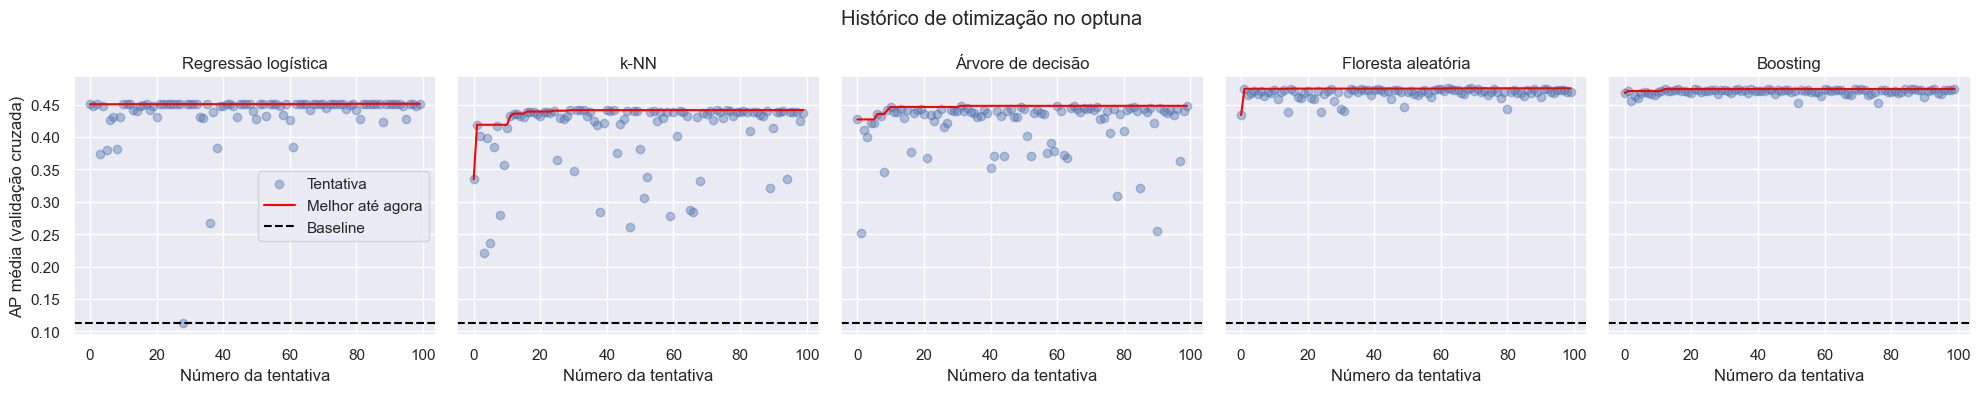

In [27]:
fig, eixos = plt.subplots(1, 5, figsize=(20, 4), sharey=True)

for eixo, (nome, (estudo, _)) in zip(eixos, estudos.items()):
    df_trials = estudo.trials_dataframe()
    df_trials = df_trials.loc[df_trials["state"] == "COMPLETE"]

    eixo.scatter(df_trials["number"], df_trials["value"], alpha=0.4, label="Tentativa")
    eixo.plot(
        df_trials["number"], df_trials["value"].cummax(), color="red", label="Melhor até agora"
    )
    eixo.axhline(AP_BASELINE_CV, linestyle="--", color="black", label="Baseline")

    eixo.set(title=nome, xlabel="Número da tentativa")

eixos[0].set_ylabel("AP média (validação cruzada)")
eixos[0].legend(loc="center right")
fig.suptitle("Histórico de otimização no optuna")
fig.tight_layout()

> **O que os resultados mostram.** Em todos os algoritmos a melhor AP estabiliza bem antes da tentativa 100, então 100 tentativas bastaram para estes espaços de busca. A regressão logística quase não evolui, e algumas tentativas ficam bem abaixo (uma perto do baseline). $k$-NN e árvore ganham mais com a busca. Floresta e boosting têm tentativas concentradas numa faixa estreita (≈ 0,44 a 0,475), ou seja, são pouco sensíveis aos hiperparâmetros. Todos ficam muito acima do baseline (≈ 0,11).

O `optuna` consegue estimar a **importância de cada hiperparâmetro**, isto é, quanto cada um explica da variação da função objetivo ao longo das tentativas (a estimativa é feita com uma floresta aleatória ajustada sobre o histórico das tentativas, ver referência [5]). Hiperparâmetros muito importantes merecem atenção em ajustes futuros do espaço de busca.

> **O que esta célula faz.** Calcula, para cada estudo, a importância de cada hiperparâmetro (`get_param_importances`) e a mostra em barras horizontais. Quanto maior a barra, mais a variação daquele hiperparâmetro explica a variação da AP entre as tentativas. É uma importância *dentro do espaço de busca que definimos*: uma barra pequena pode significar apenas que o intervalo escolhido era estreito.

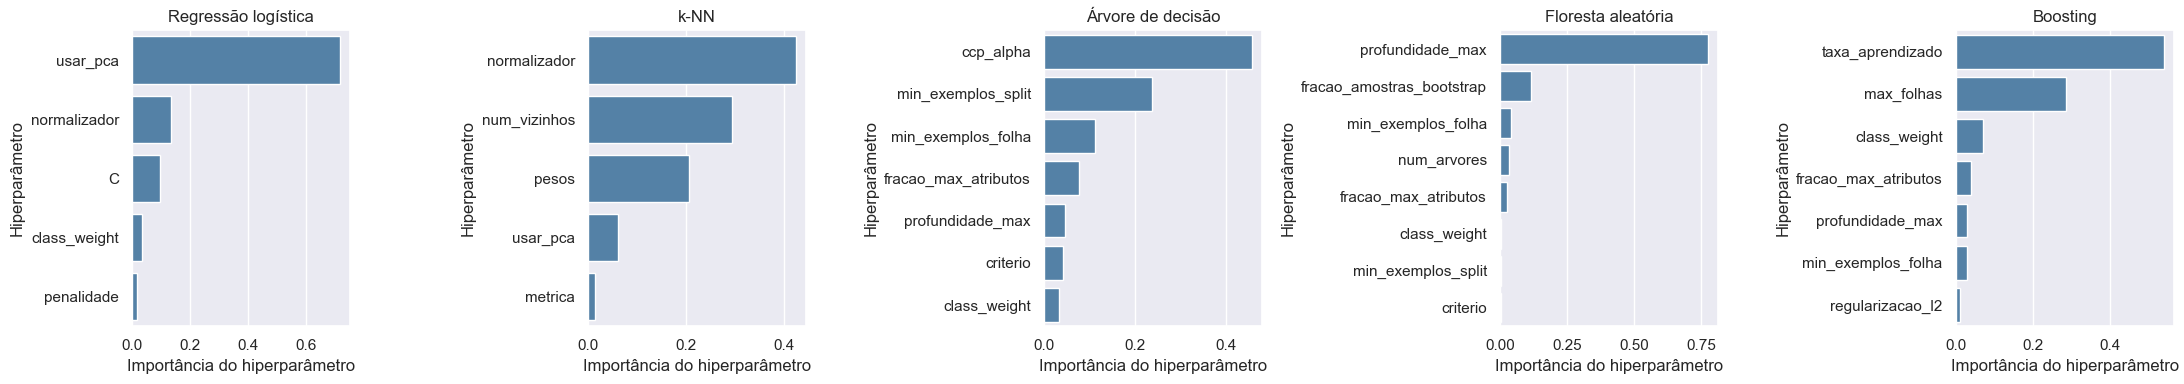

In [28]:
from optuna.importance import get_param_importances

# calculadas uma única vez (o cálculo é estocástico) e reutilizadas na seção 13
IMPORTANCIAS_HP = {nome: get_param_importances(estudo) for nome, (estudo, _) in estudos.items()}

fig, eixos = plt.subplots(1, 5, figsize=(22, 4))

for eixo, (nome, (estudo, _)) in zip(eixos, estudos.items()):
    importancias_hp = IMPORTANCIAS_HP[nome]

    sns.barplot(
        x=list(importancias_hp.values()),
        y=list(importancias_hp.keys()),
        orient="h",
        ax=eixo,
        color="steelblue",
    )
    eixo.set(title=nome, xlabel="Importância do hiperparâmetro", ylabel="Hiperparâmetro")

fig.tight_layout()

> **O que os resultados mostram.** Na regressão logística domina `usar_pca` (≈ 0,7); como o melhor trial não usa PCA, isso sugere que ativá-lo piora o resultado na maioria dos casos. No $k$-NN, normalizador (≈ 0,4) e número de vizinhos (≈ 0,3) pesam mais, ou seja, a escala importa tanto quanto $k$. Na árvore, `ccp_alpha` (≈ 0,45). Na floresta, `profundidade_max` (≈ 0,8). No boosting, `taxa_aprendizado` (≈ 0,55) e `max_folhas`. Os hiperparâmetros que mais importam são os de complexidade e regularização; `class_weight` e `criterio` quase não importam. Isso vale só dentro do espaço de busca definido.

### 10.3 Comparação por validação cruzada repetida

Para comparar os algoritmos de forma menos otimista, avaliamos o modelo com os melhores hiperparâmetros de cada estudo (e o baseline) por validação cruzada de 5 folds **repetida 3 vezes com sementes diferentes** (15 avaliações por algoritmo). Cada repetição usa uma partição diferente dos dados de treino (sempre estratificada e agrupada). Isso nos dá uma **distribuição** de desempenho, e não um único número, permitindo comparar a diferença entre algoritmos com a variabilidade natural da validação.

> **O que esta célula faz.** Define `avalia_cv_repetida` (repete a validação cruzada estratificada e agrupada com sementes diferentes) e a executa para o baseline e para as 5 melhores configurações: 6 modelos × 3 repetições × 5 folds = 90 treinos. Monta `tabela_cv` com a média e o desvio padrão da AP e da AUC de cada algoritmo, ordenada pela AP média. Esta é a comparação que decide o algoritmo escolhido.

In [29]:
def avalia_cv_repetida(cria_modelo, X, y, grupos, num_repeticoes):
    """Repete a validação cruzada estratificada e agrupada com sementes diferentes.

    Args:
      cria_modelo: função sem argumentos que devolve um modelo novo.
      X: DataFrame de atributos.
      y: Series com o target.
      grupos: grupos de exemplos redundantes (nunca separados entre folds).
      num_repeticoes: número de repetições da validação cruzada.

    Returns:
      DataFrame com uma linha por (repetição, fold) e as colunas AP e AUC.
    """

    resultados = []

    for repeticao in range(num_repeticoes):
        particionador = StratifiedGroupKFold(
            n_splits=NUM_FOLDS,
            shuffle=True,
            random_state=SEMENTE_ALEATORIA + 1 + repeticao,
        )
        folds_repeticao = list(particionador.split(X, y, groups=grupos))

        metricas = avalia_cv(cria_modelo, X, y, folds_repeticao)
        metricas["Repetição"] = repeticao + 1
        resultados.append(metricas)

    return pd.concat(resultados, ignore_index=True)


criadores = {"Baseline": cria_baseline, **criadores_otimizados}

resultados_cv = []

for nome, cria_modelo in criadores.items():
    metricas = avalia_cv_repetida(
        cria_modelo, X_treino, y_treino, grupos_treino.values, NUM_REPETICOES_CV
    )
    metricas["Algoritmo"] = nome
    resultados_cv.append(metricas)

df_resultados_cv = pd.concat(resultados_cv, ignore_index=True)

tabela_cv = (
    df_resultados_cv.groupby("Algoritmo")[["AP", "AUC"]]
    .agg(["mean", "std"])
    .sort_values(("AP", "mean"), ascending=False)
)

tabela_cv.round(4)

AP             AUC        
                       mean     std    mean     std
Algoritmo                                          
Boosting             0.4739  0.0182  0.8057  0.0074
Floresta aleatória   0.4693  0.0164  0.8022  0.0091
Regressão logística  0.4508  0.0208  0.7921  0.0088
Árvore de decisão    0.4422  0.0178  0.7806  0.0107
k-NN                 0.4404  0.0154  0.7893  0.0080
Baseline             0.1121  0.0031  0.5000  0.0000

> **O que os resultados mostram.** Pela AP: boosting (0,4739 ± 0,0182), floresta (0,4693 ± 0,0164), regressão logística (0,4508 ± 0,0208), árvore (0,4422 ± 0,0178) e $k$-NN (0,4404 ± 0,0154); baseline 0,1121 ± 0,0031. Na ROC-AUC o topo é o mesmo (0,806 e 0,802), mas $k$-NN (0,789) passa a árvore (0,781). A diferença boosting–floresta (0,0046) é bem menor que o desvio padrão, e a diferença para a regressão logística (≈ 0,023) é só um pouco maior que ele: só o baseline é claramente pior. Os 15 valores por algoritmo não são independentes (as repetições reutilizam os mesmos exemplos), então os desvios subestimam a incerteza real.

> **O que esta célula faz.** Desenha boxplots da AP e da AUC dos 15 resultados (5 folds × 3 repetições) de cada algoritmo, na ordem da AP média. A largura de cada caixa mostra a variabilidade, e é ela que permite avaliar se duas diferenças de média são reais.

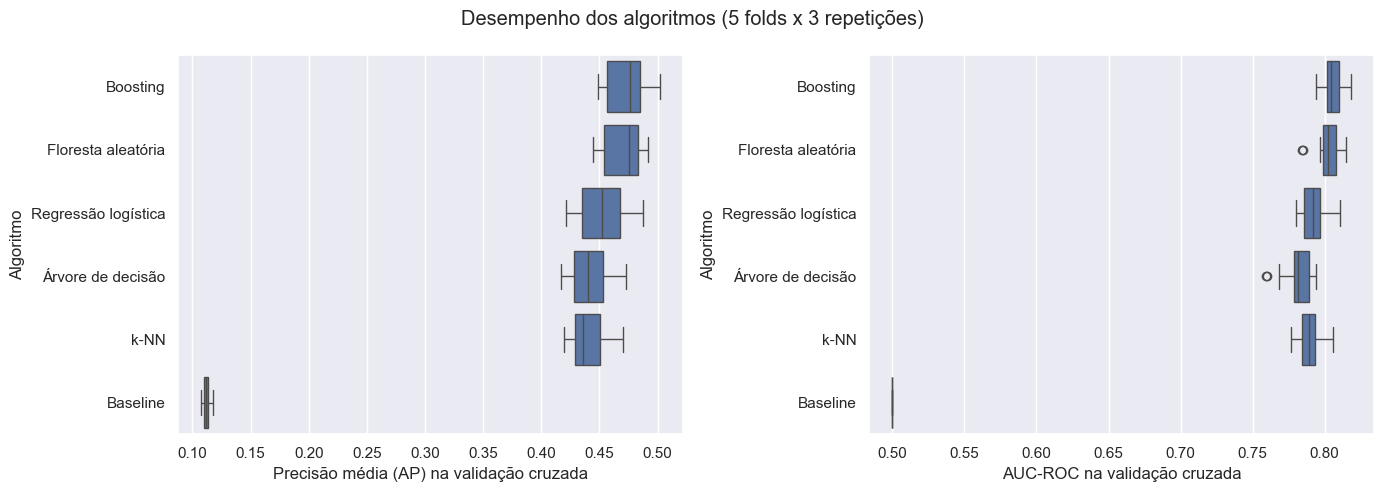

In [30]:
ordem_algoritmos = tabela_cv.index.tolist()

fig, eixos = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(
    data=df_resultados_cv, x="AP", y="Algoritmo", order=ordem_algoritmos, orient="h", ax=eixos[0]
)
eixos[0].set(xlabel="Precisão média (AP) na validação cruzada", ylabel="Algoritmo")

sns.boxplot(
    data=df_resultados_cv, x="AUC", y="Algoritmo", order=ordem_algoritmos, orient="h", ax=eixos[1]
)
eixos[1].set(xlabel="ROC-AUC na validação cruzada", ylabel="Algoritmo")

fig.suptitle("Desempenho dos algoritmos (5 folds x 3 repetições)")
fig.tight_layout()

> **O que os resultados mostram.** As caixas de boosting e floresta quase se sobrepõem por completo, e a da regressão logística se sobrepõe a ambas. Árvore e $k$-NN ficam um degrau abaixo, mas também sobrepostas à logística. Na ROC-AUC as caixas são mais estreitas e a separação entre as duas primeiras e o restante é um pouco mais nítida, ainda com sobreposição. O baseline está isolado (AP ≈ 0,11 e ROC-AUC = 0,5, sem variação, pois não ordena ninguém).

> **O que esta célula faz.** Seleciona o melhor e o segundo colocados (sem o baseline), compara a diferença de AP entre eles com o desvio padrão do primeiro e imprime se é um empate técnico (diferença menor que um desvio padrão) ou uma vantagem consistente. Aqui é definida a variável `nome_melhor`, usada em todo o restante do notebook.

In [31]:
# A escolha do melhor algoritmo é feita aqui, só com a validação cruzada do treino
algoritmos_sem_baseline = [a for a in ordem_algoritmos if a != "Baseline"]

nome_melhor = algoritmos_sem_baseline[0]
nome_segundo = algoritmos_sem_baseline[1]

ap_melhor = tabela_cv.loc[nome_melhor, ("AP", "mean")]
ap_segundo = tabela_cv.loc[nome_segundo, ("AP", "mean")]
dp_melhor = tabela_cv.loc[nome_melhor, ("AP", "std")]

print(f"Melhor algoritmo pela validação cruzada: {nome_melhor} (AP = {ap_melhor:.4f})")
print(f"Segundo colocado: {nome_segundo} (AP = {ap_segundo:.4f})")
print(f"Diferença entre os dois: {ap_melhor - ap_segundo:.4f} (desvio padrão do primeiro: {dp_melhor:.4f})")

if (ap_melhor - ap_segundo) < dp_melhor:
    print("A diferença é menor que um desvio padrão: tecnicamente, há um empate entre os dois.")
else:
    print("A diferença é maior que um desvio padrão: a vantagem do primeiro é consistente.")

Melhor algoritmo pela validação cruzada: Boosting (AP = 0.4739)
Segundo colocado: Floresta aleatória (AP = 0.4693)
Diferença entre os dois: 0.0046 (desvio padrão do primeiro: 0.0182)
A diferença é menor que um desvio padrão: tecnicamente, há um empate entre os dois.


> **O que os resultados mostram.** O boosting é o escolhido pela regra definida (maior AP média na validação cruzada), mas a diferença para a floresta é cerca de 4 vezes menor que o desvio padrão: é um empate técnico. A escolha segue o protocolo, não uma superioridade comprovada, e não será revista depois de olhar o teste.

## 11. Avaliação final no conjunto de teste

Chegou a hora de usar o conjunto de teste, **uma única vez**. O algoritmo "oficial" é o escolhido na seção anterior (`nome_melhor`), com base **apenas** na validação cruzada. Mostramos o desempenho de todos os modelos no teste por transparência, mas não voltaremos atrás para trocar o escolhido por um que se saiu melhor no teste (isso seria vazamento de dados: usar o teste para escolher modelo).

Cada modelo é treinado com **todo o conjunto de treino** e avaliado no teste.

> **O que esta célula faz.** É a primeira e única vez que o conjunto de teste é usado. Treina o baseline e os 5 modelos otimizados com **todo** o treino, prevê as probabilidades no teste e calcula AP e AUC. Também estima um intervalo de confiança de 95% da AP por bootstrap (500 reamostragens do teste). A `tabela_teste` junta AP no teste, IC95%, AUC e a AP da validação cruzada, para comparação.

In [32]:
modelos_finais = {}
probabilidades_teste = {}

for nome, cria_modelo in criadores.items():
    modelo = cria_modelo()
    modelo.fit(X_treino, y_treino)

    modelos_finais[nome] = modelo
    probabilidades_teste[nome] = modelo.predict_proba(X_teste)[:, 1]

# Intervalos de confiança por bootstrap (reamostragem dos exemplos do teste)
NUM_REAMOSTRAGENS = 500
gerador = np.random.default_rng(SEMENTE_ALEATORIA)

y_teste_arr = y_teste.values
indices_boot = [
    gerador.integers(0, len(y_teste_arr), len(y_teste_arr)) for _ in range(NUM_REAMOSTRAGENS)
]

linhas = []

for nome, y_prob in probabilidades_teste.items():
    ap_boot = [average_precision_score(y_teste_arr[i], y_prob[i]) for i in indices_boot]
    metricas = calcula_metricas(y_teste_arr, y_prob)

    linhas.append(
        {
            "Algoritmo": nome,
            "AP (teste)": metricas["AP"],
            "AP IC95% inf.": np.percentile(ap_boot, 2.5),
            "AP IC95% sup.": np.percentile(ap_boot, 97.5),
            "ROC-AUC (teste)": metricas["AUC"],
            "AP (CV)": tabela_cv.loc[nome, ("AP", "mean")],
        }
    )

tabela_teste = pd.DataFrame(linhas).set_index("Algoritmo").sort_values("AP (teste)", ascending=False)

tabela_teste.round(4)

,AP (teste),AP IC95% inf.,AP IC95% sup.,ROC-AUC (teste),AP (CV)
Algoritmo,,,,,
Floresta aleatória,0.4717,0.4392,0.5064,0.7938,0.4693
Boosting,0.4711,0.4384,0.5054,0.8026,0.4739
Regressão logística,0.4537,0.4209,0.4879,0.7894,0.4508
k-NN,0.4356,0.4047,0.4680,0.7839,0.4404
Árvore de decisão,0.4321,0.4008,0.4663,0.7761,0.4422
Baseline,0.1150,0.1075,0.1215,0.5000,0.1121


> **O que os resultados mostram.** No teste, floresta (AP 0,4717) e boosting (0,4711) seguem empatados, e o boosting lidera em ROC-AUC (0,803 contra 0,794). Os ICs de 95% dos cinco algoritmos se sobrepõem, então com este teste não dá para afirmar qual é o melhor; só o baseline (0,115) fica separado. As AP do teste diferem das da validação cruzada em no máximo ≈ 0,01, então a validação cruzada estimou bem o desempenho em dados novos do mesmo período, sem sobreajuste ao processo de otimização. A troca de posição entre floresta e boosting não muda a escolha, pois o critério foi fixado antes.

Verificação: o boosting final parou antes do limite de 1000 iterações? Com taxa de aprendizado baixa (≈ 0,011), ele pode precisar de muitas árvores.

In [ ]:
modelo_boosting_final = modelos_finais["Boosting"]
print(f"Iterações usadas pelo boosting final: {modelo_boosting_final[-1].n_iter_} (limite: 1000)")

As colunas `AP IC95%` mostram um intervalo de confiança de 95% obtido por **bootstrap** (reamostragem com reposição dos exemplos do teste, 500 vezes): se os intervalos de dois algoritmos se sobrepõem bastante, **não podemos afirmar** que um é melhor que o outro com base neste conjunto de teste. Compare também a coluna `AP (teste)` com `AP (CV)`: valores parecidos indicam que a validação cruzada estimou bem o desempenho em dados novos (ou seja, não houve sobreajuste ao processo de otimização).

### 11.1 Curvas ROC e de precisão $\times$ sensibilidade

> **O que esta célula faz.** Plota, para todos os modelos no teste, a curva ROC (à esquerda) e a curva precisão × sensibilidade (à direita). As linhas tracejadas são as referências: o sorteio na ROC e a proporção de positivos na curva PR.

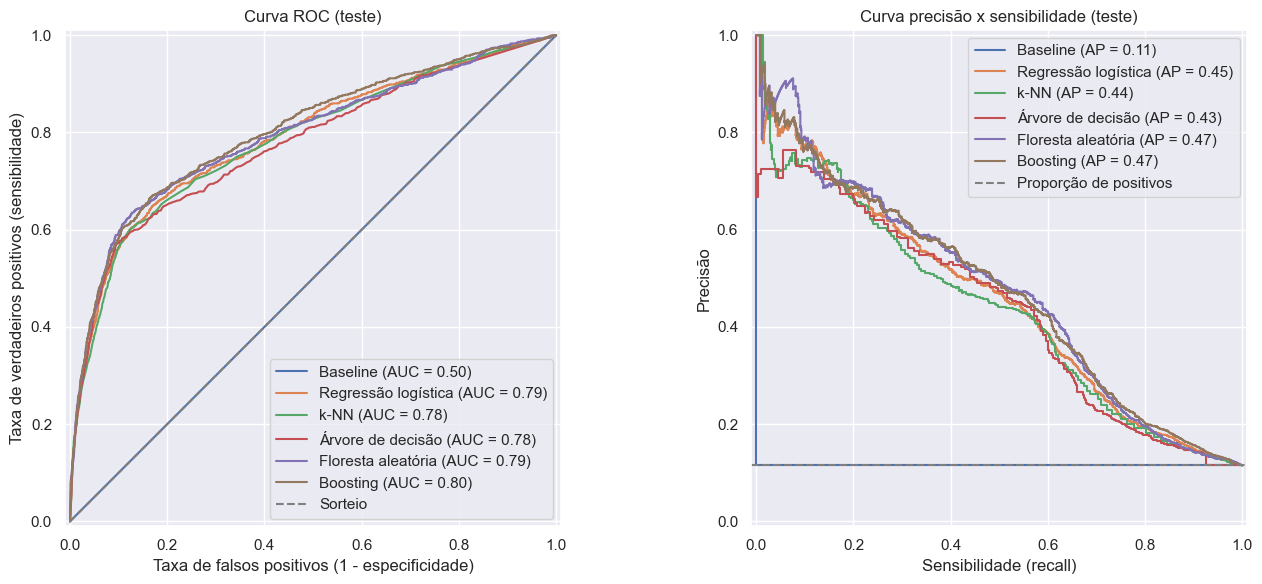

In [33]:
from sklearn.metrics import PrecisionRecallDisplay, RocCurveDisplay

fig, eixos = plt.subplots(1, 2, figsize=(14, 6))

for nome, y_prob in probabilidades_teste.items():
    RocCurveDisplay.from_predictions(y_teste, y_prob, name=nome, ax=eixos[0])
    PrecisionRecallDisplay.from_predictions(y_teste, y_prob, name=nome, ax=eixos[1])

eixos[0].plot([0, 1], [0, 1], linestyle="--", color="gray", label="Sorteio")
eixos[0].set(
    xlabel="Taxa de falsos positivos (1 - especificidade)",
    ylabel="Taxa de verdadeiros positivos (sensibilidade)",
    title="Curva ROC (teste)",
)
eixos[0].legend(loc="lower right")

eixos[1].axhline(y_teste.mean(), linestyle="--", color="gray", label="Proporção de positivos")
eixos[1].set(
    xlabel="Sensibilidade (recall)",
    ylabel="Precisão",
    title="Curva precisão x sensibilidade (teste)",
)
eixos[1].legend(loc="upper right")

fig.tight_layout()

> **O que os resultados mostram.** As curvas ROC ficam bem acima da diagonal e quase coladas, com boosting e floresta ligeiramente por cima e a árvore um pouco abaixo. Na curva PR o trade-off é claro: precisão ≈ 0,65 com sensibilidade 0,2, ≈ 0,5 com 0,6 e ≈ 0,2 ao tentar capturar quase todos os positivos. Para sensibilidade < 0,1 as curvas oscilam muito (poucos exemplos), então a precisão alta ali não é confiável. Todos ficam acima do baseline (0,115).

### 11.2 O limiar de decisão

Até agora comparamos modelos por métricas que **não dependem de limiar**. Para efetivamente decidir "ligar ou não ligar", precisamos de um **limiar de probabilidade**: se $P(y=1|X) \ge$ limiar, ligamos. O limiar padrão de 0,5 é, em geral, **inadequado em problemas desbalanceados**: como as probabilidades previstas costumam ser baixas (a taxa base é 11%), quase nenhum cliente ultrapassa 0,5 e o modelo quase nunca "ativa".

Escolher o limiar também é uma etapa de modelagem, logo **não pode usar o teste**. Escolhemos o limiar que **maximiza a estatística F1** (média harmônica entre precisão e sensibilidade) nas **previsões fora da amostra do treino**, isto é, as previsões obtidas na validação cruzada, em que cada exemplo é previsto por um modelo que nunca o viu. Só depois, o limiar escolhido é aplicado ao teste.

> O limiar que maximiza o F1 dá o mesmo peso a precisão e sensibilidade. Em uma aplicação real, o banco escolheria o limiar pelo **custo** de cada ligação frente ao **lucro** de cada adesão. O F1 é aqui apenas um critério objetivo e justificável.

> **O que esta célula faz.** Escolhe o limiar de decisão sem tocar no teste: gera, para o modelo escolhido, previsões "fora da amostra" no treino (cada cliente é previsto por um modelo que não o viu), calcula precisão, sensibilidade e F1 para cada limiar possível e guarda em `LIMIAR_ESCOLHIDO` o que maximiza o F1. Plota as três curvas com o limiar escolhido marcado.

Limiar que maximiza o F1 nas previsões fora da amostra: 0.225


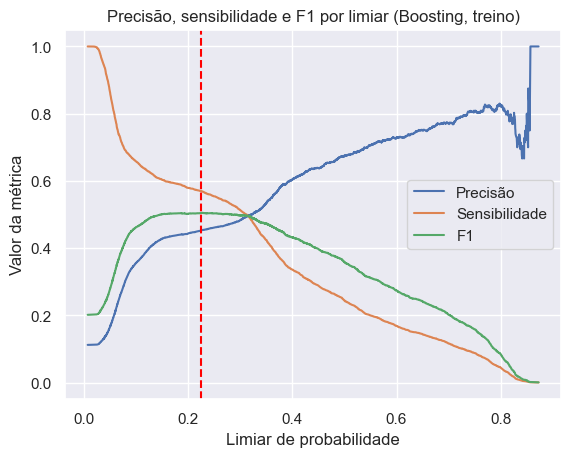

In [34]:
from sklearn.metrics import precision_recall_curve


def probabilidades_fora_da_amostra(cria_modelo, X, y, folds):
    """Probabilidades de cada exemplo de treino previstas por um modelo que não o viu."""

    y_prob = np.zeros(len(y))

    for indice_treino_cv, indice_val_cv in folds:
        modelo = cria_modelo()
        modelo.fit(X.iloc[indice_treino_cv], y.iloc[indice_treino_cv])
        y_prob[indice_val_cv] = modelo.predict_proba(X.iloc[indice_val_cv])[:, 1]

    return y_prob


prob_oof = probabilidades_fora_da_amostra(criadores[nome_melhor], X_treino, y_treino, FOLDS)

precisoes, sensibilidades, limiares = precision_recall_curve(y_treino, prob_oof)

with np.errstate(divide="ignore", invalid="ignore"):
    f1 = 2 * precisoes * sensibilidades / (precisoes + sensibilidades)

f1 = np.nan_to_num(f1)

# a última precisão/sensibilidade não tem limiar associado
indice_melhor_limiar = np.argmax(f1[:-1])
LIMIAR_ESCOLHIDO = limiares[indice_melhor_limiar]

print(f"Limiar que maximiza o F1 nas previsões fora da amostra: {LIMIAR_ESCOLHIDO:.3f}")

eixo = sns.lineplot(x=limiares, y=precisoes[:-1], label="Precisão")
sns.lineplot(x=limiares, y=sensibilidades[:-1], label="Sensibilidade", ax=eixo)
sns.lineplot(x=limiares, y=f1[:-1], label="F1", ax=eixo)
eixo.axvline(LIMIAR_ESCOLHIDO, linestyle="--", color="red", label="Limiar escolhido")
eixo.set(
    xlabel="Limiar de probabilidade",
    ylabel="Valor da métrica",
    title=f"Precisão, sensibilidade e F1 por limiar ({nome_melhor}, treino)",
);

> **O que os resultados mostram.** O limiar que maximiza o F1 nas previsões fora da amostra é 0,225, bem abaixo de 0,5, como esperado com 11% de positivos. Nesse ponto, precisão ≈ 0,45, sensibilidade ≈ 0,57 e F1 ≈ 0,50. A curva do F1 é achatada entre ≈ 0,15 e ≈ 0,3, então o ótimo não é nítido, e a escolha final deveria vir de custos reais (seção 13.2). A precisão sobe a ≈ 0,8 em limiares altos, mas a sensibilidade desaba.

> **O que esta célula faz.** Aplica o modelo escolhido ao teste com dois limiares, o padrão (0,5) e o escolhido, e mostra uma matriz de confusão para cada um. Depois imprime o relatório de classificação (precisão, sensibilidade e F1 por classe) com o limiar escolhido.

Relatório de classificação no teste (Boosting, limiar = 0.23):

              precision    recall  f1-score   support

  Não aderiu       0.94      0.91      0.93      7305
      Aderiu       0.46      0.56      0.50       949

    accuracy                           0.87      8254
   macro avg       0.70      0.74      0.71      8254
weighted avg       0.89      0.87      0.88      8254



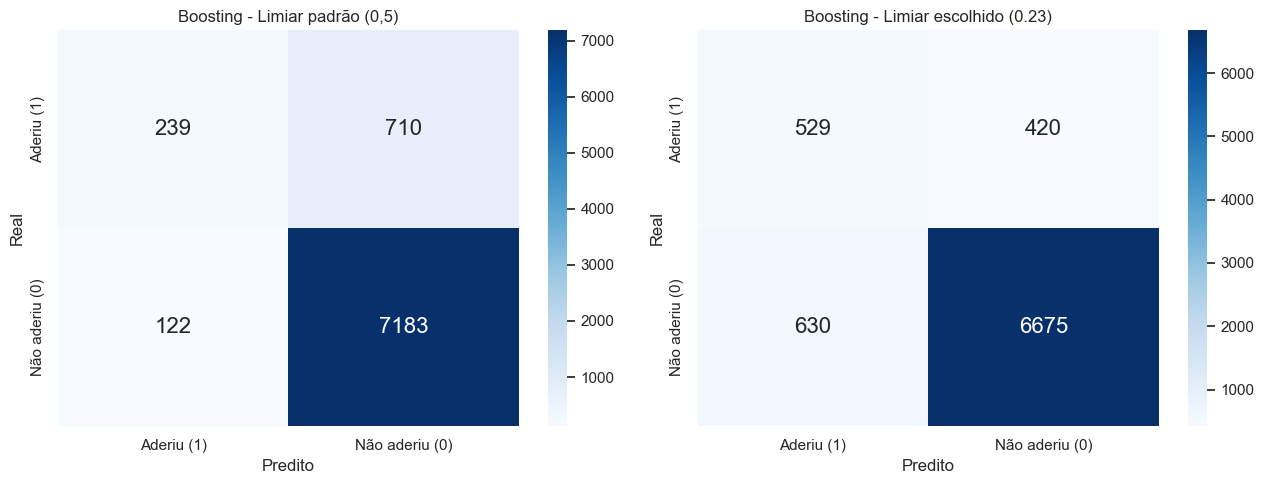

In [35]:
from sklearn.metrics import classification_report, confusion_matrix, f1_score, precision_score, recall_score

modelo_melhor = modelos_finais[nome_melhor]
prob_melhor_teste = probabilidades_teste[nome_melhor]

ordem_labels = [1, 0]
nomes_labels = ["Aderiu (1)", "Não aderiu (0)"]

fig, eixos = plt.subplots(1, 2, figsize=(13, 5))

for eixo, limiar, titulo in zip(
    eixos, [0.5, LIMIAR_ESCOLHIDO], ["Limiar padrão (0,5)", f"Limiar escolhido ({LIMIAR_ESCOLHIDO:.2f})"]
):
    y_previsto = (prob_melhor_teste >= limiar).astype(int)

    matriz_conf = confusion_matrix(y_teste, y_previsto, labels=ordem_labels)
    df_conf = pd.DataFrame(matriz_conf, nomes_labels, nomes_labels)

    sns.heatmap(df_conf, annot=True, fmt="d", annot_kws={"size": 16}, cmap="Blues", ax=eixo)
    eixo.set(xlabel="Predito", ylabel="Real", title=f"{nome_melhor} - {titulo}")

fig.tight_layout()

y_previsto = (prob_melhor_teste >= LIMIAR_ESCOLHIDO).astype(int)

print(f"Relatório de classificação no teste ({nome_melhor}, limiar = {LIMIAR_ESCOLHIDO:.2f}):\n")
print(classification_report(y_teste, y_previsto, target_names=["Não aderiu", "Aderiu"]))

> **O que os resultados mostram.** Com limiar 0,5, o modelo marca 361 clientes e acerta 239 (precisão ≈ 66%), mas perde 710 dos 949 que aderiram (sensibilidade ≈ 25%). Com 0,225, marca 1.159: acerta 529 (precisão ≈ 46%, sensibilidade ≈ 56%, F1 = 0,50) e erra 630 (falsos positivos). Esses valores são parecidos com os do treino, então o limiar generalizou. A acurácia cai de ≈ 0,90 para 0,87, abaixo dos ≈ 0,885 do baseline no teste, mas o modelo passa a encontrar mais da metade dos que aderem. É o argumento da seção 6.1: acurácia não é a métrica certa aqui.

### 11.3 Utilidade prática: curva de ganho acumulado

Uma forma muito intuitiva de enxergar o valor de um modelo de ranqueamento é a **curva de ganho acumulado**. Se o banco ligar primeiro aos clientes com maior probabilidade prevista, que fração do total de adesões ele captura ao ligar para apenas uma fração dos clientes? Sem modelo (ligações em ordem aleatória), ligar para 20% dos clientes captura, em média, 20% das adesões (a diagonal do gráfico).

> **O que esta célula faz.** Define `curva_ganho` e plota a curva de ganho acumulado dos modelos (com destaque para o escolhido) contra a diagonal, que representa ligar em ordem aleatória. Imprime quanto das adesões o modelo escolhido captura ao ligar para os 10%, 20% e 30% de clientes com maior probabilidade.

Contatando os 10% de clientes com maior probabilidade, o modelo Boosting captura 45.3% das adesões (ganho de 4.53x em relação ao acaso).
Contatando os 20% de clientes com maior probabilidade, o modelo Boosting captura 63.6% das adesões (ganho de 3.18x em relação ao acaso).
Contatando os 30% de clientes com maior probabilidade, o modelo Boosting captura 71.5% das adesões (ganho de 2.38x em relação ao acaso).


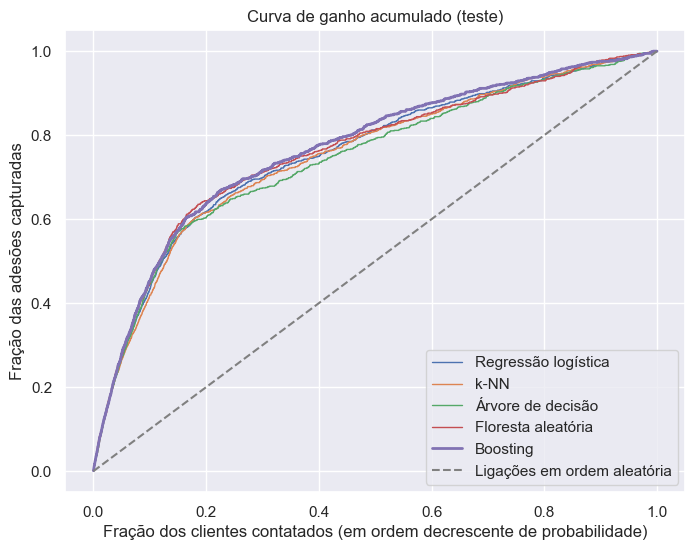

In [36]:
def curva_ganho(y_verdadeiro, y_prob):
    """Fração acumulada de positivos capturados ao contatar os clientes em ordem decrescente de probabilidade."""

    ordem = np.argsort(-y_prob)
    y_ordenado = np.asarray(y_verdadeiro)[ordem]

    fracao_contatada = np.arange(1, len(y_ordenado) + 1) / len(y_ordenado)
    fracao_capturada = np.cumsum(y_ordenado) / y_ordenado.sum()

    return fracao_contatada, fracao_capturada


fig, eixo = plt.subplots(figsize=(8, 6))

for nome, y_prob in probabilidades_teste.items():
    if nome == "Baseline":
        continue
    x_ganho, y_ganho = curva_ganho(y_teste, y_prob)
    eixo.plot(x_ganho, y_ganho, label=nome, linewidth=2 if nome == nome_melhor else 1)

eixo.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Ligações em ordem aleatória")
eixo.set(
    xlabel="Fração dos clientes contatados (em ordem decrescente de probabilidade)",
    ylabel="Fração das adesões capturadas",
    title="Curva de ganho acumulado (teste)",
)
eixo.legend(loc="lower right")

x_ganho, y_ganho = curva_ganho(y_teste, prob_melhor_teste)

for fracao in [0.1, 0.2, 0.3]:
    indice = int(fracao * len(y_ganho)) - 1
    print(
        f"Contatando os {fracao * 100:.0f}% de clientes com maior probabilidade, o modelo "
        f"{nome_melhor} captura {y_ganho[indice] * 100:.1f}% das adesões "
        f"(ganho de {y_ganho[indice] / fracao:.2f}x em relação ao acaso)."
    )

> **O que os resultados mostram.** Ligando só aos 10% com maior probabilidade, o banco captura 45,3% das adesões (4,5× o acaso); com 20%, 63,6% (3,2×); com 30%, 71,5% (2,4×). Ou seja, com 20% das ligações perde-se ≈ 36% das adesões e evitam-se 80% das ligações. As curvas são quase indistinguíveis nos primeiros ≈ 15%; depois, boosting e floresta ficam no topo e a árvore mais abaixo.

## 12. Explicação do modelo escolhido

Um modelo que apenas "acerta" não basta: queremos saber **no que ele se baseia**. Usamos duas ferramentas de explicação do `scikit-learn`, aplicadas ao modelo escolhido (já treinado em todo o conjunto de treino).

### 12.1 Importância por permutação

**Como funciona** [11]: para medir a importância de um atributo, **embaralhamos aleatoriamente os valores daquele atributo** no conjunto de avaliação (o que destrói sua relação com o target, mantendo sua distribuição) e medimos **quanto o desempenho cai**. Se a AP despenca, o modelo dependia muito daquele atributo; se quase não muda, o atributo era pouco útil. O procedimento é repetido várias vezes para estimar a variabilidade.

Vantagens: funciona para **qualquer modelo** e, aplicada a um `Pipeline`, embaralha os atributos **originais** (não as colunas `one-hot`). Cuidado: se dois atributos são muito correlacionados (como os indicadores macroeconômicos), embaralhar um deles pode ter pouco efeito, porque o modelo "usa o outro" no lugar, e a importância fica diluída entre os dois.

Aplicamos no conjunto de teste, que é o desempenho que nos interessa em dados novos (a explicação **não** é usada para escolher nada).

> **O que esta célula faz.** Calcula a importância por permutação do modelo escolhido no teste: cada um dos 20 atributos originais é embaralhado 10 vezes e mede-se a queda da AP. Plota boxplots ordenados por importância e imprime os 8 atributos mais importantes.

nr.employed     0.0663
euribor3m       0.0331
month           0.0293
emp.var.rate    0.0229
contact         0.0219
day_of_week     0.0118
campaign        0.0089
poutcome        0.0083
dtype: float64

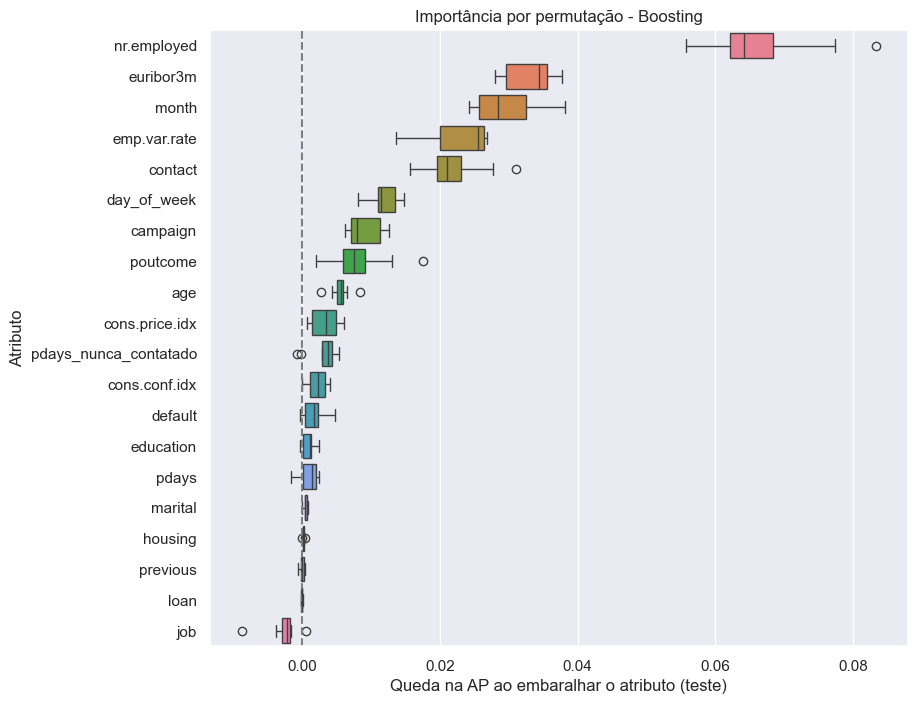

In [37]:
from sklearn.inspection import PartialDependenceDisplay, permutation_importance

NUM_REPETICOES_PERMUTACAO = 10

resultado_perm = permutation_importance(
    modelo_melhor,
    X_teste,
    y_teste,
    scoring="average_precision",
    n_repeats=NUM_REPETICOES_PERMUTACAO,
    random_state=SEMENTE_ALEATORIA,
    n_jobs=-1,
)

df_perm = pd.DataFrame(resultado_perm.importances.T, columns=ATRIBUTOS)
ordem_importancia = df_perm.mean().sort_values(ascending=False).index.tolist()

fig, eixo = plt.subplots(figsize=(9, 8))

sns.boxplot(data=df_perm.reindex(ordem_importancia, axis=1), orient="h", ax=eixo)
eixo.axvline(0, linestyle="--", color="gray")
eixo.set(
    xlabel="Queda na AP ao embaralhar o atributo (teste)",
    ylabel="Atributo",
    title=f"Importância por permutação - {nome_melhor}",
)

df_perm.mean().sort_values(ascending=False).head(8).round(4)

> **O que os resultados mostram.** A maior queda de AP vem de `nr.employed` (≈ 0,066), seguido de `euribor3m` (0,033), `month` (0,029), `emp.var.rate` (0,023) e `contact` (0,022); depois `day_of_week` (0,012), `campaign` (0,009) e `poutcome` (0,008). `previous`, `loan`, `housing`, `marital` e `pdays` ficam ≈ 0, e `job` é levemente negativo (o modelo provavelmente ajustou ruído nele). O histórico do cliente pesa pouco porque está dividido entre atributos redundantes, e os indicadores macro também dividem importância entre si (correlação > 0,9). O modelo se apoia sobretudo em *quando* o cliente foi contatado, o que reforça a limitação temporal da seção 13.2. `day_of_week` tem importância moderada apesar de taxas quase planas na EDA e de uma variação pequena na dependência parcial.

### 12.2 Gráficos de dependência parcial

**Como funciona** [9, 10]: a dependência parcial mostra **o efeito médio de um atributo na previsão do modelo**. Para um atributo $x_j$, fixamos $x_j$ em cada valor possível de uma grade, para **todos** os exemplos, calculamos a previsão do modelo e tiramos a média. A curva resultante mostra como a probabilidade média prevista muda com $x_j$, "marginalizando" os demais atributos. Para atributos categóricos, o gráfico mostra uma barra por categoria.

Limitação: o método assume que o atributo analisado é independente dos demais; com atributos correlacionados, a grade pode incluir combinações irreais (por exemplo, `euribor3m` altíssimo com `emp.var.rate` baixíssimo). Plotamos os 6 atributos mais importantes segundo a permutação, usando uma amostra de 1.500 exemplos do teste para acelerar o cálculo.

> **O que esta célula faz.** Pega os 6 atributos mais importantes na permutação e desenha o gráfico de dependência parcial de cada um (calculado sobre 1.500 exemplos do teste). Atributos numéricos viram curvas; categóricos, barras.

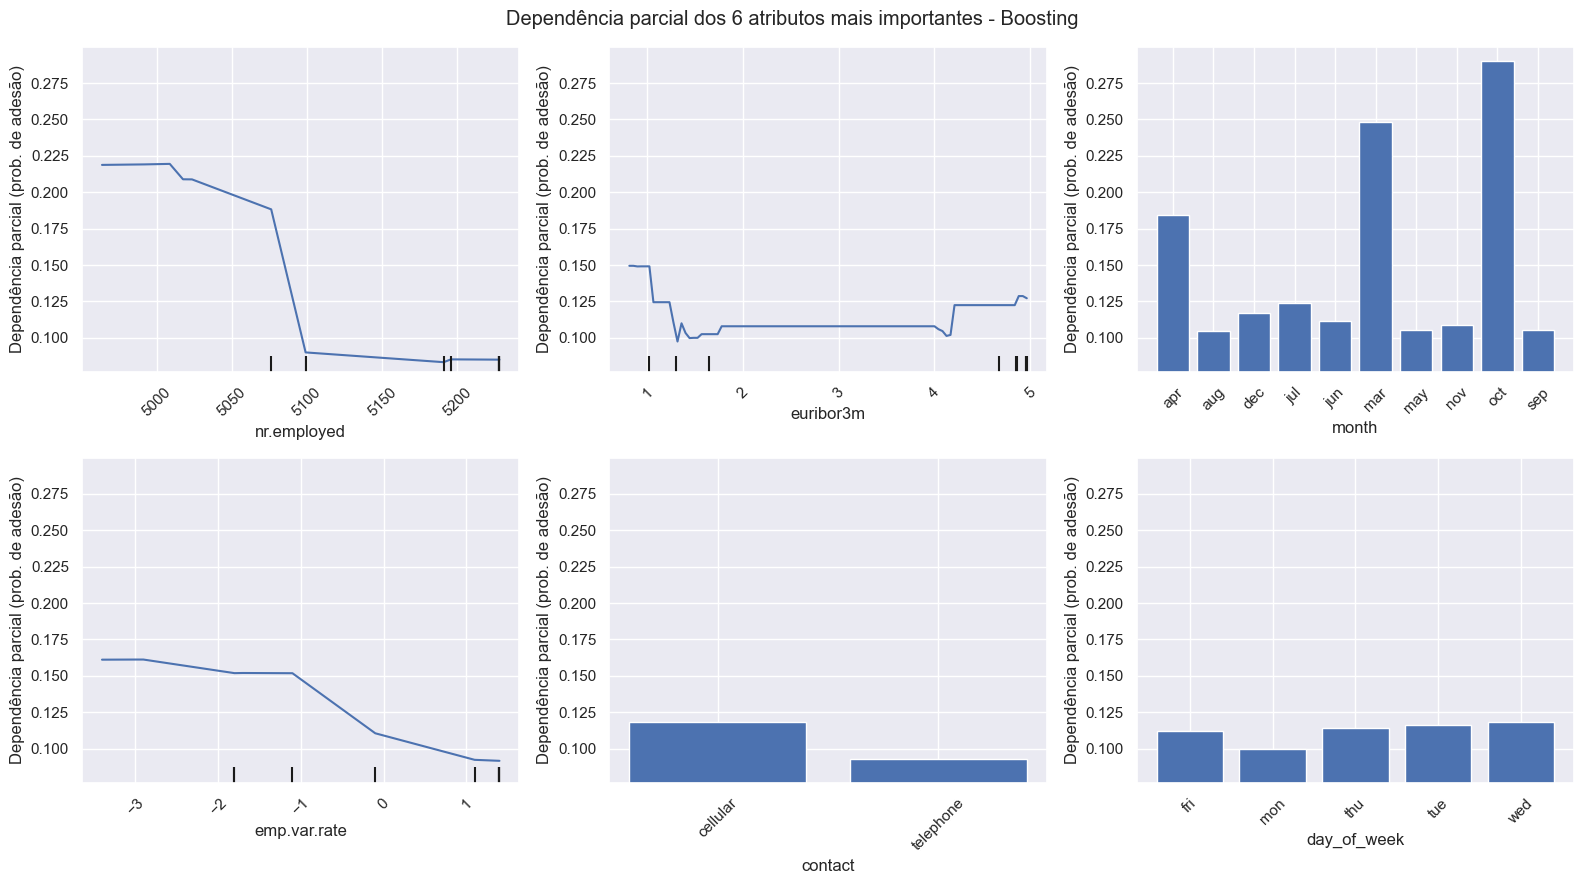

In [38]:
atributos_top = ordem_importancia[:6]
categoricos_top = [a for a in atributos_top if a in ATRIBUTOS_CATEGORICOS]

X_amostra = X_teste.sample(1500, random_state=SEMENTE_ALEATORIA)

fig, eixos = plt.subplots(2, 3, figsize=(16, 9))

PartialDependenceDisplay.from_estimator(
    modelo_melhor,
    X_amostra,
    features=atributos_top,
    categorical_features=categoricos_top,
    kind="average",
    ax=eixos.ravel(),
)

for eixo in eixos.ravel():
    eixo.set_ylabel("Dependência parcial (prob. de adesão)")
    eixo.tick_params(axis="x", labelrotation=45)

fig.suptitle(f"Dependência parcial dos 6 atributos mais importantes - {nome_melhor}")
fig.tight_layout()

> **O que os resultados mostram.** `nr.employed`: probabilidade ≈ 0,22 abaixo de ~5.075 e queda abrupta para ≈ 0,09 acima de 5.100 (degraus, pois o atributo tem poucos valores distintos). `emp.var.rate`: cai de ≈ 0,16 para ≈ 0,09 ao passar de valores negativos a positivos, coerente com a EDA (adesão maior em juros baixos). `euribor3m`: ≈ 0,15 perto de 1, ≈ 0,10 entre 1,3 e 1,6 e ≈ 0,11 até 4, com leve alta perto de 5 (padrão não monótono, possivelmente artefato da correlação com `nr.employed`; a dependência parcial assume independência). `month`: outubro (≈ 0,29), março (≈ 0,25) e abril (≈ 0,18) se destacam, o mesmo padrão da EDA. `contact`: celular (≈ 0,12) > fixo (≈ 0,09). `day_of_week`: efeito mínimo. O eixo y não começa em zero nas barras, o que exagera diferenças pequenas. Isso descreve o que o modelo aprendeu, não causalidade.

## 13. Discussão dos resultados

A célula abaixo resume de forma automática os resultados mais importantes, para que o texto da discussão sempre reflita os números **desta execução**.

> **O que esta célula faz.** Resume automaticamente os resultados principais: algoritmo escolhido, AP e AUC no teste contra o baseline, rankings na validação cruzada e no teste, diferença entre a AP da CV e a do teste, IC95%, hiperparâmetros mais importantes por algoritmo, atributos mais importantes e uso de PCA. Por ser gerada por código, sempre reflete a execução atual.

In [39]:
ap_teste_melhor = tabela_teste.loc[nome_melhor, "AP (teste)"]
auc_teste_melhor = tabela_teste.loc[nome_melhor, "ROC-AUC (teste)"]
ap_teste_baseline = tabela_teste.loc["Baseline", "AP (teste)"]

print(f"1) Algoritmo escolhido (validação cruzada): {nome_melhor}")
print(
    f"2) No teste: AP = {ap_teste_melhor:.3f} (baseline: {ap_teste_baseline:.3f}, "
    f"ou seja, {ap_teste_melhor / ap_teste_baseline:.1f}x o baseline) e ROC-AUC = {auc_teste_melhor:.3f}."
)

ordem_teste = tabela_teste.index.tolist()
ordem_teste.remove("Baseline")
print(f"3) Ranking no teste (AP): {', '.join(ordem_teste)}")
print(f"   Ranking na validação cruzada (AP): {', '.join(algoritmos_sem_baseline)}")

diferenca_cv_teste = tabela_teste.loc[nome_melhor, "AP (CV)"] - ap_teste_melhor
print(f"4) Diferença entre a AP na CV e no teste do escolhido: {diferenca_cv_teste:+.3f}")

ic_inf = tabela_teste.loc[nome_melhor, "AP IC95% inf."]
ic_sup = tabela_teste.loc[nome_melhor, "AP IC95% sup."]
print(f"5) IC95% da AP no teste: [{ic_inf:.3f}, {ic_sup:.3f}]")

print("6) Hiperparâmetros mais importantes por algoritmo (segundo o optuna):")
for nome, (estudo, _) in estudos.items():
    top2 = list(IMPORTANCIAS_HP[nome].items())[:2]
    print(f"   - {nome}: " + ", ".join(f"{p} ({v:.2f})" for p, v in top2))

print("7) Os 3 atributos mais importantes (permutação):", ", ".join(ordem_importancia[:3]))

print("8) Uso de PCA nos melhores modelos que o permitiam:")
for nome in ["Regressão logística", "k-NN"]:
    parametros = estudos[nome][0].best_params
    if parametros["usar_pca"]:
        print(f"   - {nome}: usou PCA preservando {parametros['fracao_variancia_pca'] * 100:.1f}% da variância")
    else:
        print(f"   - {nome}: não usou PCA")

1) Algoritmo escolhido (validação cruzada): Boosting
2) No teste: AP = 0.471 (baseline: 0.115, ou seja, 4.1x o baseline) e ROC-AUC = 0.803.
3) Ranking no teste (AP): Floresta aleatória, Boosting, Regressão logística, k-NN, Árvore de decisão
   Ranking na validação cruzada (AP): Boosting, Floresta aleatória, Regressão logística, Árvore de decisão, k-NN
4) Diferença entre a AP na CV e no teste do escolhido: +0.003
5) IC95% da AP no teste: [0.438, 0.505]
6) Hiperparâmetros mais importantes por algoritmo (segundo o optuna):
   - Regressão logística: usar_pca (0.75), normalizador (0.10)
   - k-NN: normalizador (0.42), num_vizinhos (0.33)
   - Árvore de decisão: ccp_alpha (0.41), min_exemplos_split (0.26)
   - Floresta aleatória: profundidade_max (0.78), fracao_amostras_bootstrap (0.11)
   - Boosting: taxa_aprendizado (0.54), max_folhas (0.18)
7) Os 3 atributos mais importantes (permutação): nr.employed, euribor3m, month
8) Uso de PCA nos melhores modelos que o permitiam:
   - Regressão logí

### 13.1 Interpretação

**Sobre o problema.** O ganho sobre o baseline é a medida real de utilidade do trabalho: o baseline representa "ligar sem critério", e a diferença entre as curvas de ganho (seção 11.3) e a diagonal mostra quantas ligações o banco poderia economizar para capturar a maior parte das adesões. Note também que a AP, mesmo para o melhor modelo, fica longe de 1: **prever adesão sem saber nada sobre a conversa telefônica é difícil**, o que é esperado após remover `duration`. É um problema com muito ruído intrínseco, que nenhum algoritmo vai eliminar.

**Sobre os algoritmos.** A expectativa da EDA era que floresta e boosting superassem o modelo linear e o $k$-NN. Os resultados confirmam isso só de forma fraca: pela validação cruzada, boosting (AP 0,4739) e floresta (0,4693) ficam à frente da regressão logística (0,4508), da árvore (0,4422) e do $k$-NN (0,4404), mas a vantagem é de cerca de 0,02 a 0,03 de AP, parecida com o desvio padrão (≈ 0,015 a 0,02). Boosting e floresta empatam (diferença de 0,0046 na validação cruzada e de 0,0006 no teste) e os intervalos de confiança do teste dos cinco algoritmos se sobrepõem, então não dá para afirmar qual é o melhor; só o baseline (AP ≈ 0,11) é claramente pior. Todos os algoritmos ficam cerca de 4 vezes acima dele. Nesse cenário de empate, o modelo mais simples, rápido e interpretável merece consideração: a regressão logística ficou a ≈ 0,02 de AP do topo. A árvore isolada ficou atrás da floresta, como esperado (a floresta é uma árvore com a variância reduzida pela média).

**Sobre os hiperparâmetros.** A otimização ajudou mais onde o ponto de partida era ruim: no $k$-NN (de AP ≈ 0,33 com $k$ = 5 para 0,44), na árvore e na floresta (limitar a profundidade levou a floresta de ≈ 0,43 para ≈ 0,47). Na regressão logística e no boosting, quase todas as tentativas já ficam perto do melhor valor. Os hiperparâmetros mais importantes são os de complexidade e regularização (`profundidade_max` na floresta, `taxa_aprendizado` no boosting, `ccp_alpha` na árvore, `usar_pca` na regressão logística): o desafio central é equilibrar *viés* e *variância* em um target ruidoso. Nenhum dos melhores modelos usou PCA.

**Sobre a explicação.** A importância por permutação mostra que o boosting se apoia sobretudo em `nr.employed` (queda de AP ≈ 0,066), `euribor3m`, `month`, `emp.var.rate` e `contact`. `poutcome`, `pdays` e `previous`, que a EDA sugeria como importantes, pesam pouco: o histórico do cliente fica dividido entre atributos redundantes. A dependência parcial indica adesão maior com `nr.employed` baixo (≈ 0,22 abaixo de ~5.075 contra ≈ 0,09 acima de 5.100), em outubro, março e abril, e em contatos por celular. Como os indicadores macroeconômicos e `month` identificam o período da campanha, o modelo usa principalmente *quando* o cliente foi contatado, o que reforça a limitação 1 da seção 13.2. Essas relações descrevem o que o modelo aprendeu, não causalidade.

**Utilidade prática.** Ligando só aos 20% de clientes com maior probabilidade, o banco captura 63,6% das adesões (3,2 vezes o acaso).

### 13.2 Limitações e cuidados

1. **Os dados têm uma dimensão temporal escondida.** Os atributos macroeconômicos, `month` e `day_of_week` atuam como proxies do período da campanha. Fizemos uma divisão aleatória (agrupada), como na disciplina, o que estima o desempenho para clientes contatados **no mesmo período histórico** do treino. Em produção, o modelo seria aplicado ao **futuro**, em um cenário econômico possivelmente diferente, e o desempenho real tende a ser **menor** que o estimado aqui. Uma validação temporal (treinar no passado, testar no futuro) seria o próximo passo, mas exige um tratamento de dados sequenciais que ainda não vimos.
2. **Um único conjunto de teste.** O teste é uma única amostra de 20% dos dados. Os intervalos de confiança por bootstrap mostram a incerteza associada a essa amostra, mas não a incerteza associada à divisão em si.
3. **Limiar escolhido por F1.** É um critério genérico; o banco deveria escolher o limiar pelos custos e benefícios reais.
4. **Busca de hiperparâmetros limitada a 100 tentativas** por algoritmo, em espaços de busca definidos por nós. Existem muitos outros hiperparâmetros e algoritmos que poderiam ser testados.
5. **Viés dos dados.** Os dados vêm de um banco português entre 2008 e 2010, em plena crise financeira. A generalização para outros países e épocas não é garantida.

## 14. Descrição do uso de IA neste trabalho

**Aluno:** Angelo Quadros Zampieri.

**Ferramenta utilizada:** majoritariamente Copilot, com algumas coisas pontuais no Chat GPT

**Como a IA foi utilizada:**(de acordo com cada IA)
**Copilot:**
- **Estrutura e texto:** a IA ajudou com a organização da estrutura do notebook e com os textos explicativos.  os blocos "O que esta célula faz" e "O que os resultados mostram", foram escritos com ajuda da IA para dar ideias de como explicar de maneira simples, e revisados pelo aluno.
- **Código:** a IA ajudou com a escrita de alguns códigos, adaptando as estratégias vistas em aula pelo aluno para que se aplicassem melhor ao trabalho.
- **Decisões de modelagem sugeridas pela IA:** Uso da precisão média (AP) como métrica de otimização e a escolha do limiar com previsões fora da amostra do treino.


## 15. Referências

1.  Moro, S.; Cortez, P.; Rita, P. A data-driven approach to predict the success of bank telemarketing. *Decision Support Systems*, v. 62, p. 22-31, 2014.

2.  UCI Machine Learning Repository. *Bank Marketing* (conjunto `bank-additional-full`). Disponível em [https://archive.ics.uci.edu/dataset/222/bank+marketing](https://archive.ics.uci.edu/dataset/222/bank+marketing).

3.  Cassar, D. R. Notebooks e slides da disciplina ATP-203 Aprendizado de Máquina (aulas de pandas, $k$-NN, divisão de dados, modelo linear e baseline, árvores e florestas, classificação binária, validação cruzada, vazamento de dados, `optuna` e pipelines, PCA, seleção de atributos e métricas). Ilum Escola de Ciência, 2026.

4.  Pedregosa, F. *et al.* Scikit-learn: Machine Learning in Python. *Journal of Machine Learning Research*, v. 12, p. 2825-2830, 2011. Documentação em [https://scikit-learn.org](https://scikit-learn.org).

5.  Akiba, T.; Sano, S.; Yanase, T.; Ohta, T.; Koyama, M. Optuna: A Next-generation Hyperparameter Optimization Framework. In: *Proceedings of the 25th ACM SIGKDD*, 2019. Documentação em [https://optuna.readthedocs.io](https://optuna.readthedocs.io).

6.  Bergstra, J.; Bardenet, R.; Bengio, Y.; Kégl, B. Algorithms for Hyper-Parameter Optimization. In: *Advances in Neural Information Processing Systems 24*, 2011.

7.  Saito, T.; Rehmsmeier, M. The Precision-Recall Plot Is More Informative than the ROC Plot When Evaluating Binary Classifiers on Imbalanced Datasets. *PLoS ONE*, v. 10, n. 3, e0118432, 2015.

8.  Breiman, L. Random Forests. *Machine Learning*, v. 45, p. 5-32, 2001.

9.  Friedman, J. H. Greedy function approximation: a gradient boosting machine. *The Annals of Statistics*, v. 29, n. 5, p. 1189-1232, 2001.

10. Hastie, T.; Tibshirani, R.; Friedman, J. *The Elements of Statistical Learning*. 2. ed. Springer, 2009.

11. Fisher, A.; Rudin, C.; Dominici, F. All Models are Wrong, but Many are Useful: Learning a Variable's Importance by Studying an Entire Class of Prediction Models Simultaneously. *Journal of Machine Learning Research*, v. 20, n. 177, p. 1-81, 2019. (A importância por permutação foi originalmente proposta por Breiman [8].)

## 16. Conclusões e principais aprendizados

O objetivo deste trabalho foi investigar se algoritmos de **aprendizado de máquina** seriam capazes de prever a adesão de clientes a depósitos a prazo em campanhas de telemarketing bancário, permitindo identificar os contatos com maior probabilidade de sucesso. Para isso, foram utilizados cinco algoritmos diferentes, com **otimização de hiperparâmetros por meio do Optuna** e avaliação por validação cruzada e por um conjunto de teste separado.

Os resultados mostraram que todos os modelos otimizados apresentaram desempenho consideravelmente superior ao *baseline*. Entre eles, o **HistGradientBoosting** e a **Floresta Aleatória** obtiveram os melhores resultados, embora a diferença entre os dois tenha sido pequena demais para afirmar que um é realmente superior ao outro. Isso também mostrou que um modelo mais complexo nem sempre representa uma vantagem significativa: a **Regressão Logística**, por exemplo, apresentou resultados relativamente próximos aos melhores modelos, sendo uma alternativa mais simples e interpretável.

Um dos resultados mais interessantes foi perceber a importância da escolha das métricas. Como apenas cerca de **11% dos clientes aderiram ao depósito**, a acurácia isoladamente poderia transmitir uma impressão enganosa sobre o desempenho dos modelos. A **precisão média (AP)** permitiu avaliar melhor a capacidade de identificar os clientes que realmente aderiram. Além disso, a **curva de ganho acumulado** mostrou uma aplicação prática dos resultados: ao priorizar os 20% dos clientes com maiores probabilidades previstas, seria possível alcançar aproximadamente **63,6% das adesões** registradas.

Outro aprendizado importante foi perceber como as decisões tomadas durante o pré-processamento podem afetar profundamente um modelo. A remoção do atributo `duration`, por exemplo, foi necessária para evitar o **vazamento de informação**, já que a duração da ligação só é conhecida depois que o contato acontece. Também foi importante compreender a necessidade de separar os dados de treino e teste, realizar o pré-processamento dentro dos *pipelines* e utilizar **validação cruzada** para comparar os algoritmos de maneira mais confiável.

A etapa de **explicação dos modelos** também trouxe resultados interessantes. A importância por permutação e os gráficos de dependência parcial mostraram que o modelo escolhido utiliza principalmente informações relacionadas ao contexto econômico e ao período da campanha. Isso permitiu ir além de simplesmente comparar métricas e observar quais características influenciam as previsões. Ao mesmo tempo, ficou evidente que essas relações não representam necessariamente causalidade e que o desempenho encontrado pode não se repetir em outros períodos ou contextos econômicos.

Por fim, este projeto permitiu colocar em prática diferentes conceitos estudados na disciplina, desde o tratamento de dados e a construção de *pipelines* até a otimização de hiperparâmetros, validação cruzada e interpretação de modelos. Também mostrou que desenvolver um modelo de aprendizado de máquina não consiste apenas em encontrar o algoritmo com a maior métrica, mas em **compreender os dados, justificar as escolhas realizadas, evitar erros metodológicos e interpretar os resultados considerando suas limitações**.

Concluo que o objetivo do trabalho foi alcançado: foi possível construir e comparar diferentes modelos capazes de identificar padrões associados à adesão dos clientes, além de demonstrar como essas previsões poderiam auxiliar na priorização de contatos. Entretanto, os resultados devem ser interpretados dentro do contexto histórico dos dados utilizados, e uma aplicação real exigiria avaliações adicionais, especialmente com dados de períodos mais recentes.